# Validating cell-type annotations

In [1]:
library(Seurat)
library(Signac)
#library(hdf5r) #need to load `hdf5_hl` on rcc
library(EnsDb.Hsapiens.v86)
library(dplyr)
library(data.table)
library(ggplot2)
options(repr.plot.width=14, repr.plot.height=8)

Attaching SeuratObject

Seurat v4 was just loaded with SeuratObject v5; disabling v5 assays and
validation routines, and ensuring assays work in strict v3/v4
compatibility mode

Signac built for for SeuratObject v4 was just loaded with SeuratObject
v5; disabling v5 assays and validation routines, and ensuring assays
work in strict v3/v4 compatibility mode

Loading required package: ensembldb

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following object is masked from ‘package:SeuratObject’:

    intersect


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownam

In [9]:
# color code
pal_atac <- readRDS("~/projects/Lung_scMultiomics_paper/data/color_codes.RDS")
pal_rna <- pal_atac
names(pal_rna)[3:4] <- c("memCD4_T", "naiCD4_T")
pal_rna[3:4] = c("#208A42", "#74c476")
ct_order <- c(
  "Naive_B",
  "Memory_B",
  "NK",
  "CD8_T",
  "naiCD4_T",
  "memCD4_T",
  "Treg",
  "Other"
)

In [44]:
source("../../code/make_plots.R")

### cross-tissue integration approach vs. separate-tissues approach

In [2]:
jaccard <- function(a, b) {
    intersection = sum(a == b, na.rm = TRUE)
    union = length(a) + length(b) - intersection
    return (c(intersection, union, intersection/union))
}

In [2]:
# Load seurat object and annotations 
#lungs <- readRDS("~/cluster/projects/u19_multiomics/AGG_lungs/all_lungs_integrated_multi.rds")
#spleens<-readRDS("~/cluster/projects/u19_multiomics/AGG_spleens/all_spleens_integrated_multi.rds")
#immune.combined <- readRDS("~/cluster/projects/u19_multiomics/analyses/lungs_spleens_WNN_processed.rds")

In [10]:
merged_meta <- immune.combined@meta.data
ct_dict <- 
    data.frame(orig = unique(merged_meta$majority_voting),
               label = c("Memory_B",
                         "NK",
                         "CD4_T",
                         "CD8_T",
                         "Th17",
                         "Other",
                         "Other",
                         "Naive_B",
                         "Treg",
                         "Other",
                         "NK",
                         "Other")) 

merged <- 
    data.frame(
        Barcode = unlist(lapply(rownames(merged_meta), function(i){strsplit(i, '_')[[1]][1]})), 
        Tissue = merged_meta$tissue.ident,
        CellType = ct_dict$label[match(merged_meta$majority_voting, ct_dict$orig)])

separate <- rbind(
     data.frame(
        Barcode = rownames(lungs@meta.data),
        Tissue = rep("lungs", nrow(lungs@meta.data)),
        CellType = ct_dict$label[match(lungs@meta.data$majority_voting, ct_dict$orig)]),
     data.frame(
        Barcode = rownames(spleens@meta.data),
        Tissue = rep("spleens", nrow(spleens@meta.data)),
        CellType = ct_dict$label[match(spleens@meta.data$majority_voting, ct_dict$orig)])
    )

In [3]:
lungs_clusters<-read.csv("~/cluster/projects//u19_multiomics//AGG_lungs/all_lungs_scRNA_Immune_low_labels.csv")
lungs@meta.data[,"majority_voting"]<-lungs_clusters$majority_voting

spleens_clusters<-read.csv("~/cluster/projects//u19_multiomics/AGG_spleens/all_spleens_rna_Immune_low_labels.csv")
spleens@meta.data[,"majority_voting"]<-spleens_clusters$majority_voting
merged_meta <- immune.combined@meta.data

In [9]:
rnameta <- readRDS("../output/rna_meta_doublet_detected.RDS")
# confirm barcodes match
barcodes <- unlist(lapply(rownames(rnameta[rnameta$tissue.ident == "lungs", ]), function(i){strsplit(i, "_")[[1]][1]}))
lungs@meta.data$IsDoublet <- rnameta$scDblFinder.class[rnameta$tissue.ident == "lungs"]
spleens@meta.data$IsDoublet <- rnameta$scDblFinder.class[rnameta$tissue.ident == "spleens"]
immune.combined$IsDoublet <- rnameta$scDblFinder.class

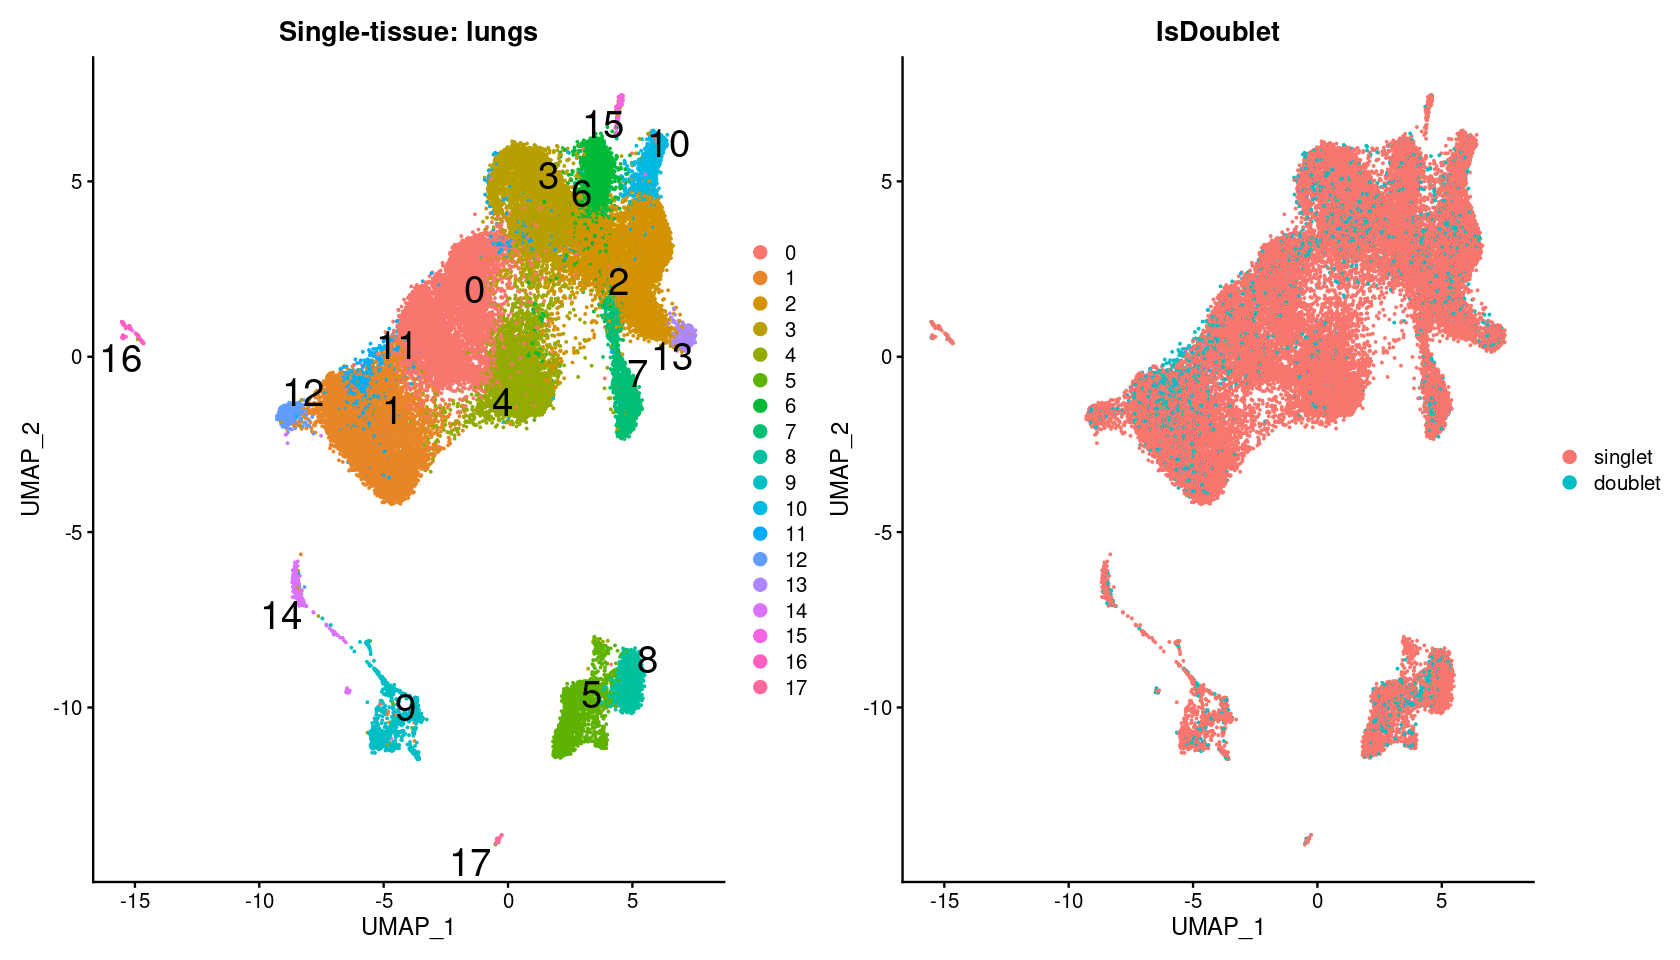

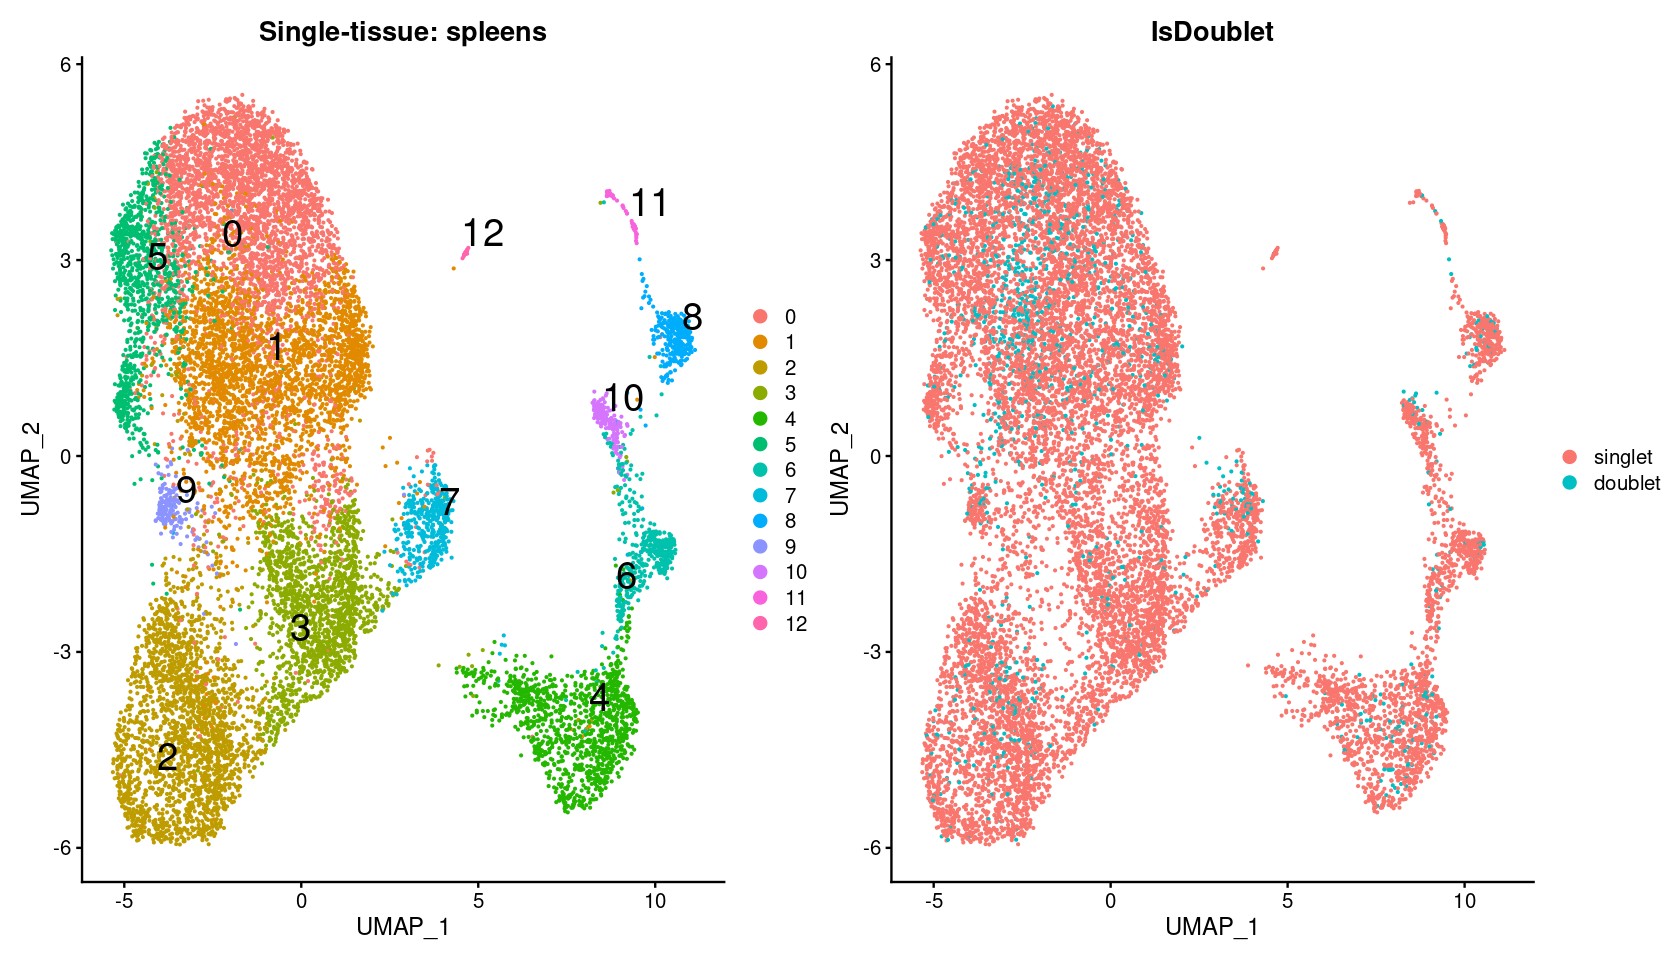

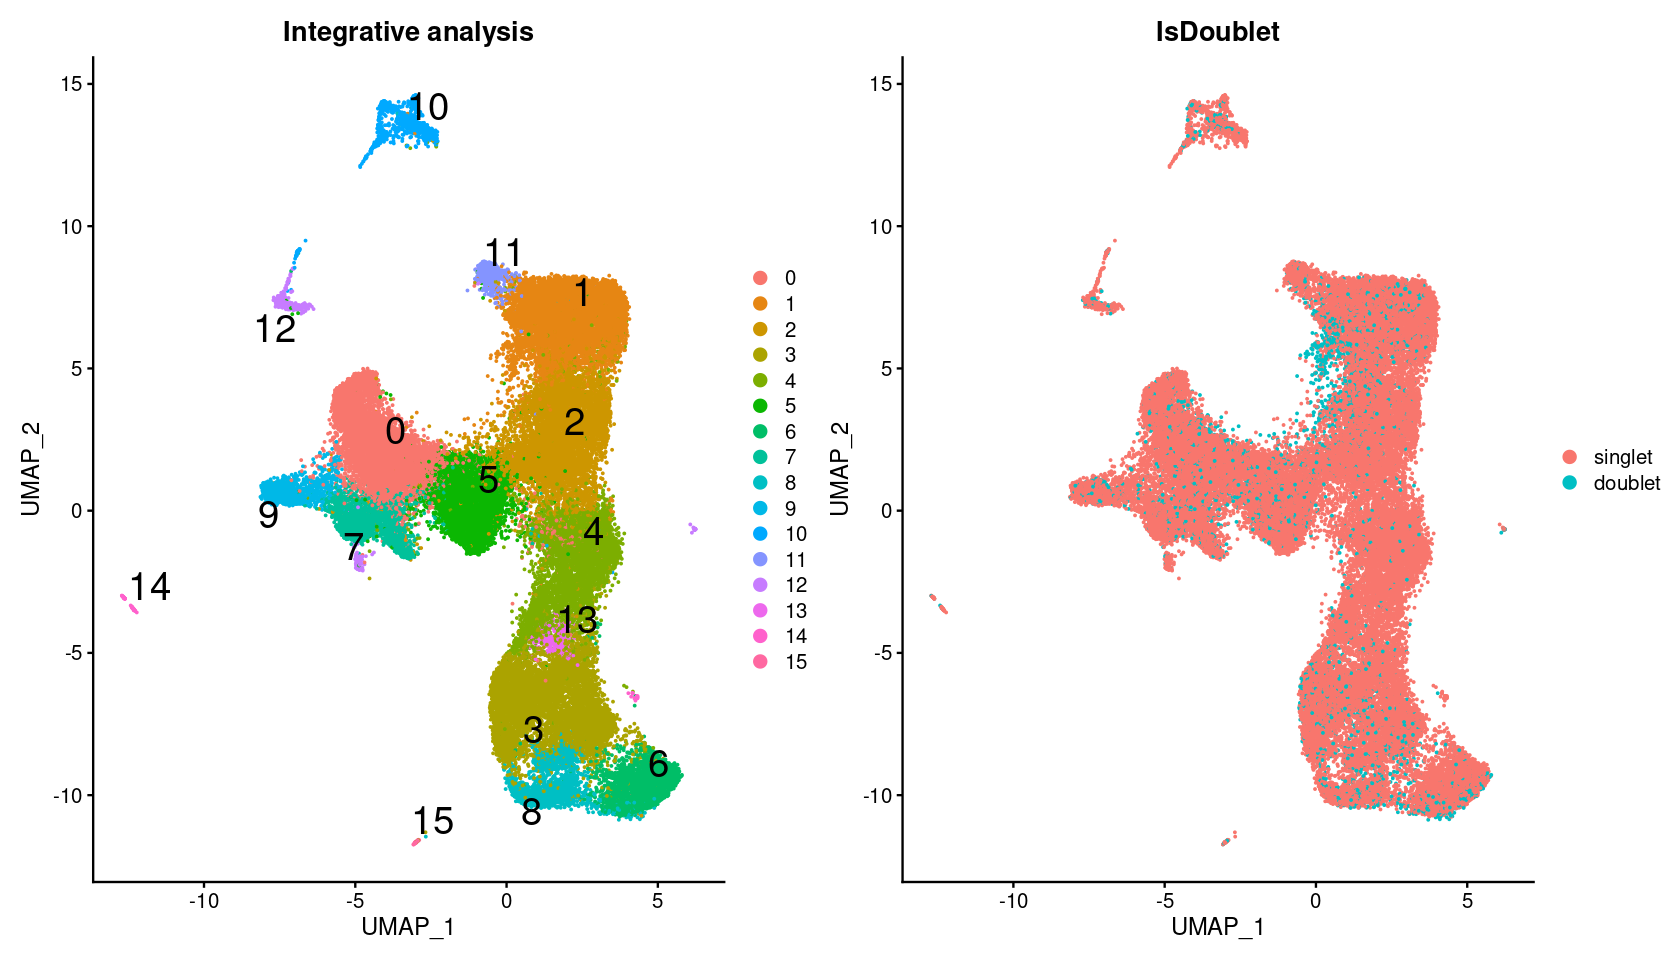

In [10]:
#lungs$SingleAnnot <- separate$CellType[separate$Tissue == "lungs"]
#spleens$SingleAnnot <- separate$CellType[separate$Tissue == "spleens"]
p1<-DimPlot(lungs, reduction = "umap", label = TRUE,label.size = 8, repel = TRUE, 
            group.by = 'integrated_snn_res.0.5') + ggtitle("Single-tissue: lungs") 
p2<-DimPlot(lungs, reduction = "umap", label = FALSE,label.size = 8, repel = TRUE, group.by = 'IsDoublet') 
p1 + p2  & theme(plot.title = element_text(hjust = 0.5))

p3<-DimPlot(spleens, reduction = "umap", label = TRUE,label.size = 8, repel = TRUE, 
            group.by = 'integrated_snn_res.0.5') + ggtitle("Single-tissue: spleens") 
p4<-DimPlot(spleens, reduction = "umap", label = FALSE,label.size = 8, repel = TRUE, group.by = 'IsDoublet')  
p3 + p4  & theme(plot.title = element_text(hjust = 0.5))

p5<-DimPlot(immune.combined, reduction = "umap", label = TRUE,label.size = 8, repel = TRUE, 
            group.by = 'integrated_snn_res.0.5') + ggtitle("Integrative analysis") 
p6<-DimPlot(immune.combined, reduction = "umap", label = FALSE,label.size = 8, repel = TRUE, group.by = 'IsDoublet')  
p5 + p6  & theme(plot.title = element_text(hjust = 0.5))


In [39]:
immune.combined$corr_integrated <- as.character(immune.combined$`integrated_snn_res.0.5`)
immune.combined$corr_integrated[as.character(immune.combined$`integrated_snn_res.0.5`) == "4" & immune.combined$tissue.ident == "lungs"] <- "4_L"
immune.combined$corr_integrated[as.character(immune.combined$`integrated_snn_res.0.5`) == "4" & immune.combined$tissue.ident == "spleens"] <- "4_S"

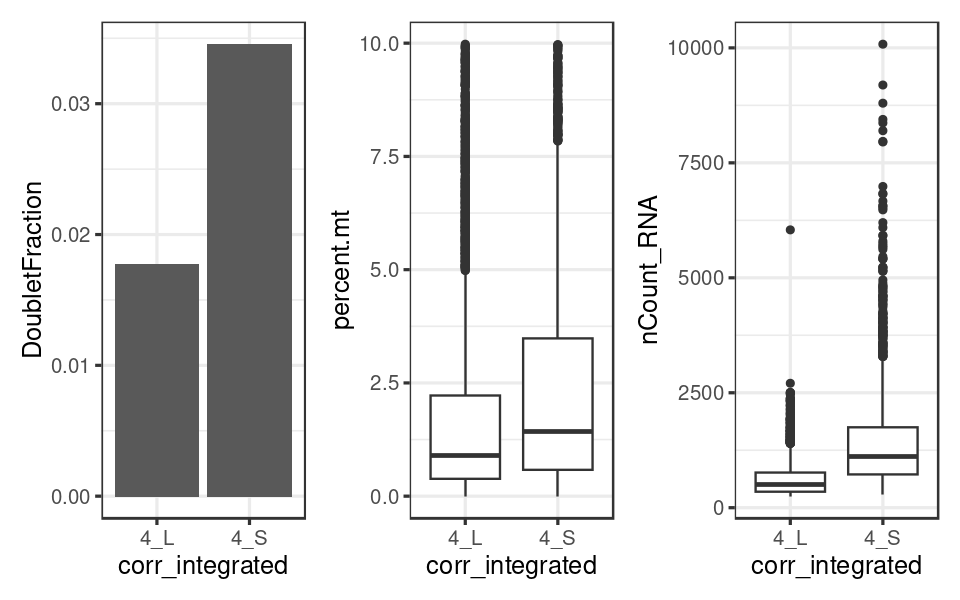

In [50]:
doublet_tab <-
    immune.combined@meta.data %>% filter(grepl("4_", corr_integrated)) %>% group_by(corr_integrated) %>% 
        summarise(DoubletFraction = sum(IsDoublet == "doublet")/length(IsDoublet))
p1 <- ggplot(doublet_tab,
       aes(x = corr_integrated, y = DoubletFraction)) + 
        geom_col() + 
        theme_bw(base_size = 15)
p2 <- ggplot(immune.combined@meta.data %>% 
             filter(grepl("4_", corr_integrated)),
             aes(y = percent.mt,
                 x = corr_integrated)) + 
        geom_boxplot() + 
        theme_bw(base_size = 15)
p3 <- ggplot(immune.combined@meta.data %>% 
             filter(grepl("4_", corr_integrated)),
             aes(y = nCount_RNA,
                 x = corr_integrated)) + 
        geom_boxplot() + 
        theme_bw(base_size = 15)
p1 + p2 + p3

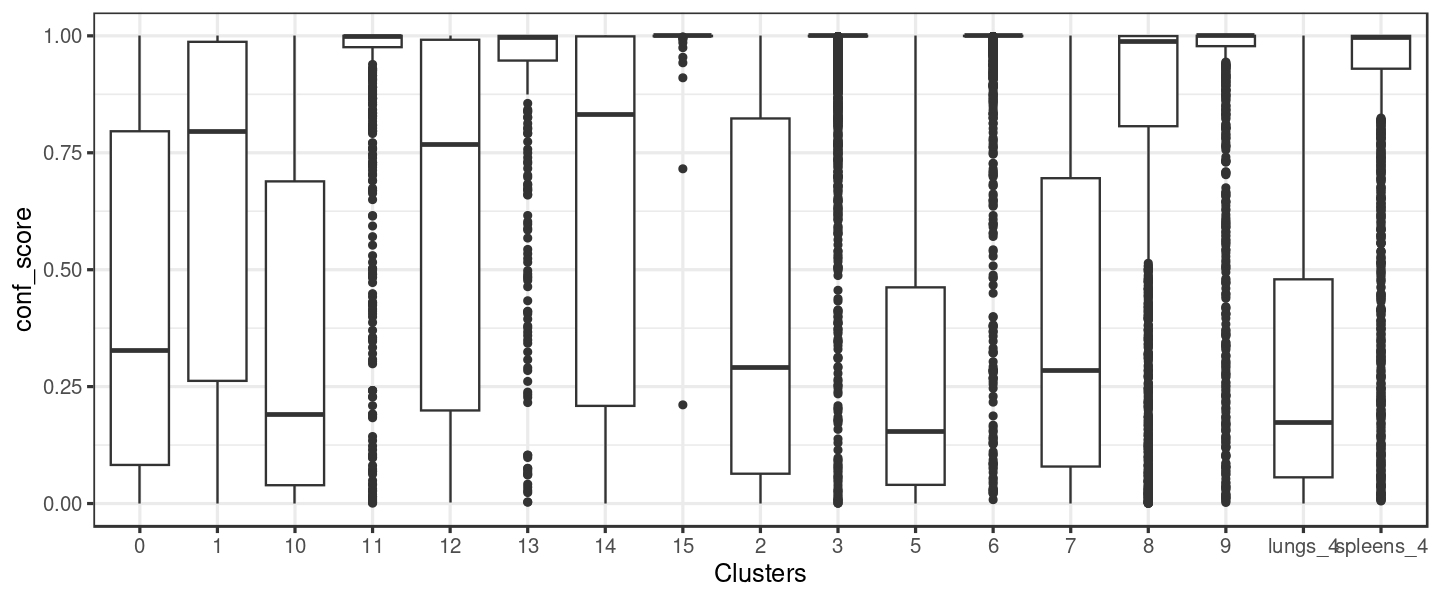

In [58]:
options(repr.plot.width=12, repr.plot.height=5)
label_pred <- fread("../output/predicted_labels_integrated_byTissue.txt")
ggplot(label_pred, 
       aes(x = over_clustering,
           y = conf_score)) + 
geom_boxplot() + xlab("Clusters") + 
theme_bw(base_size = 15)

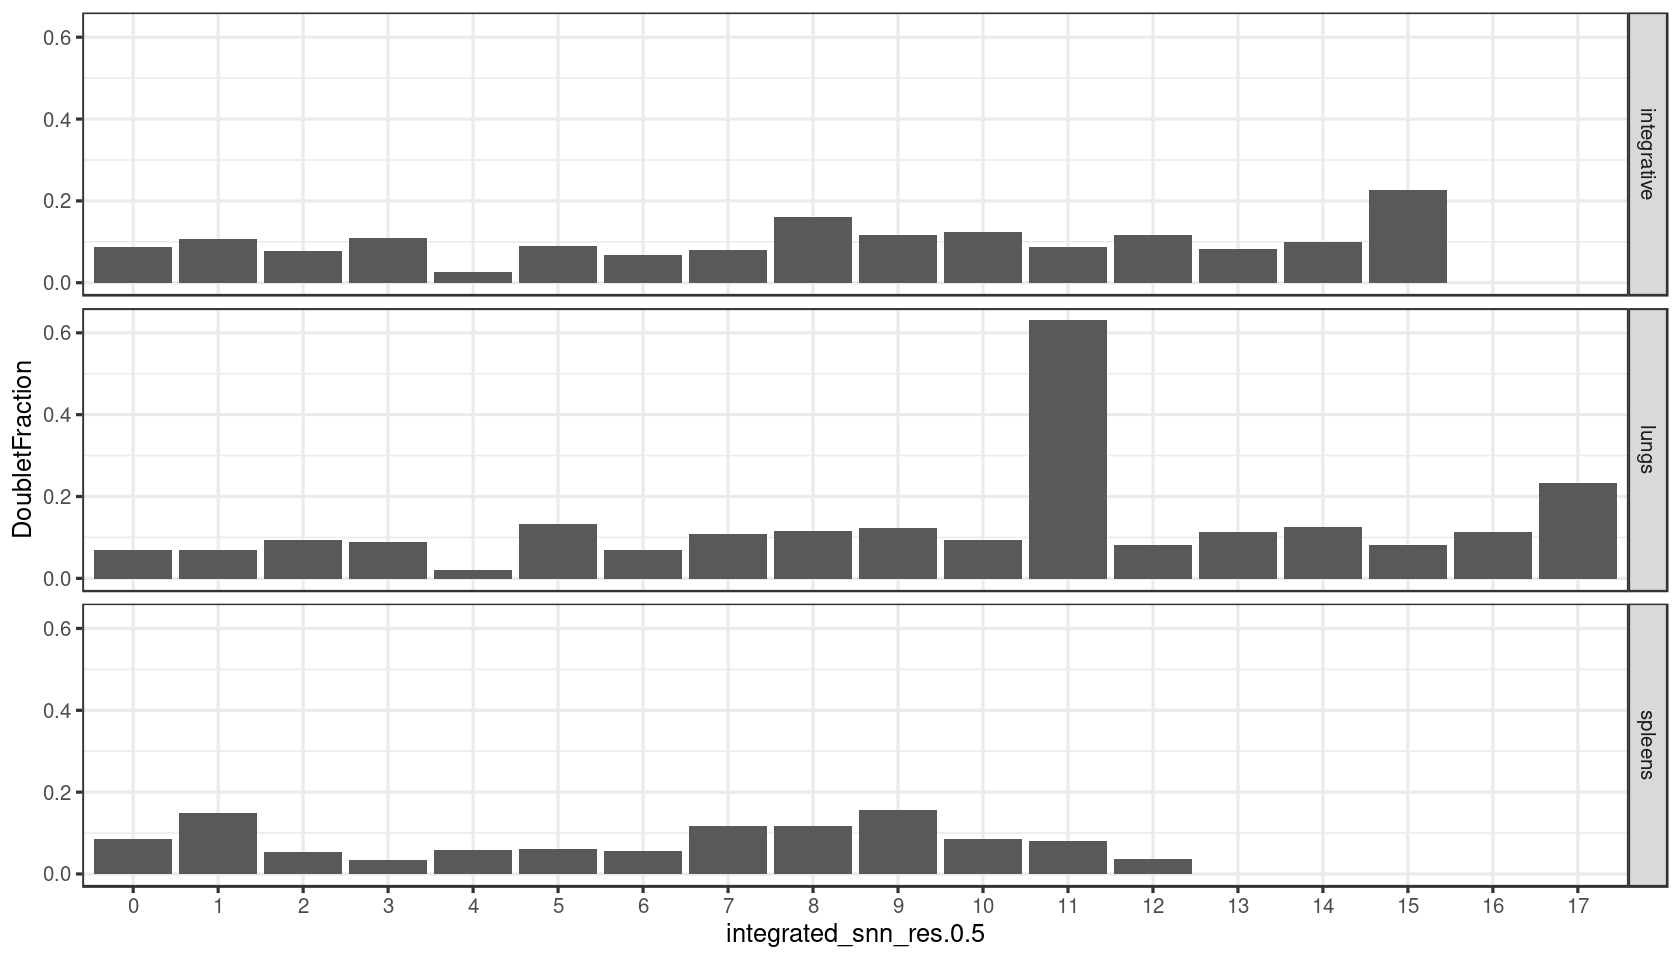

In [30]:
doublet_tab <-
    lungs@meta.data %>% group_by(integrated_snn_res.0.5) %>% 
        summarise(DoubletFraction = sum(IsDoublet == "doublet")/length(IsDoublet)) %>%
        mutate(feature = "lungs")
doublet_tab <- rbind(
    doublet_tab,
    spleens@meta.data %>% group_by(integrated_snn_res.0.5) %>% 
        summarise(DoubletFraction = sum(IsDoublet == "doublet")/length(IsDoublet)) %>%
        mutate(feature = "spleens"),
    immune.combined@meta.data %>% group_by(integrated_snn_res.0.5) %>% 
        summarise(DoubletFraction = sum(IsDoublet == "doublet")/length(IsDoublet)) %>%
        mutate(feature = "integrative")
    )

ggplot(doublet_tab, 
       aes(x = integrated_snn_res.0.5, y = DoubletFraction)) + 
        geom_col() + facet_grid(feature ~.) + 
        theme_bw(base_size = 15)

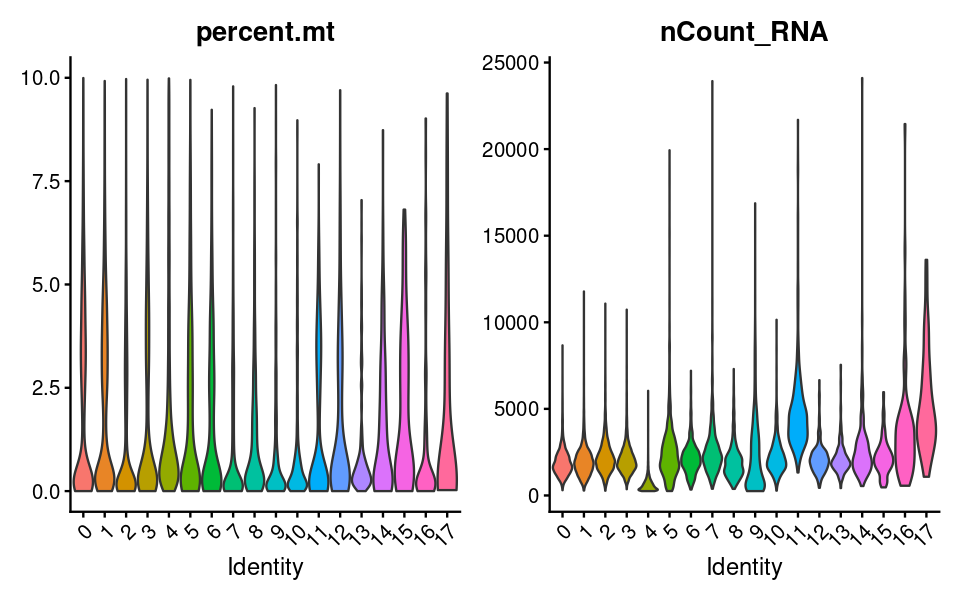

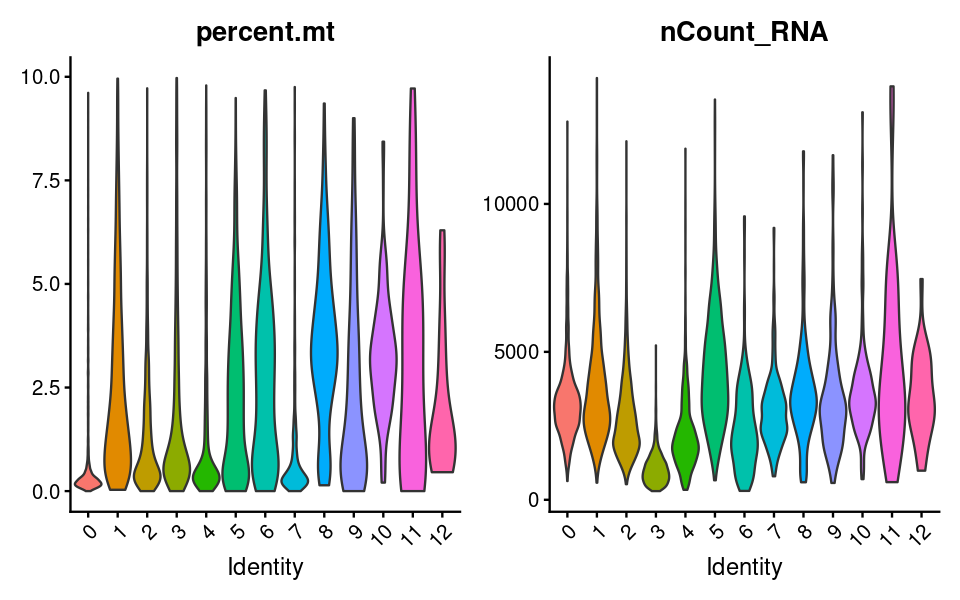

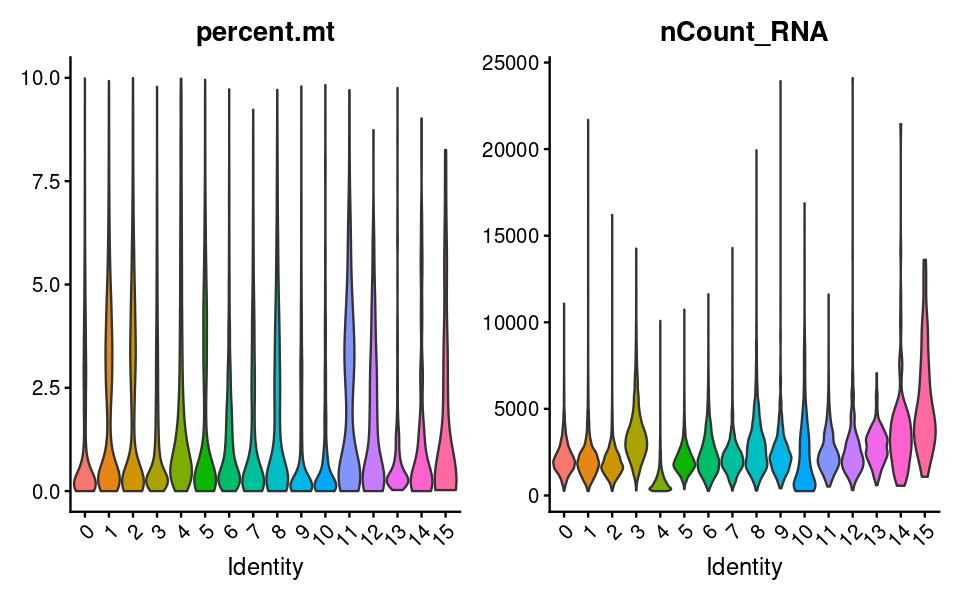

In [36]:
options(repr.plot.width=8, repr.plot.height=5)
p1 <-VlnPlot(lungs, features = c("percent.mt", "nCount_RNA"), group.by = "integrated_snn_res.0.5", pt.size = 0)
p2 <-VlnPlot(spleens, features = c("percent.mt", "nCount_RNA"), group.by = "integrated_snn_res.0.5", pt.size = 0)
p3 <-VlnPlot(immune.combined, features = c("percent.mt", "nCount_RNA"), group.by = "integrated_snn_res.0.5", pt.size = 0)
p1
p2
p3

In [3]:
immune.combined <- readRDS("../output/output_dir/remove_dup/lungs_spleens_integrated.RDS")

In [4]:
immune.combined@meta.data %>% filter(majority_voting == "Type 17 helper T cells")

,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,nCount_ATAC,nFeature_ATAC,integrated_snn_res.0.5,seurat_clusters,immune_low,lung_atlas,tissue.ident,full.ident,nCount_peaks,nFeature_peaks,majority_voting,merged,scDblFinder.class,PredCellType
,<chr>,<dbl>,<int>,<dbl>,<dbl>,<int>,<fct>,<fct>,<chr>,<chr>,<chr>,<chr>,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>
AAACAGCCACAGCCTG-2_1,2,2106,1225,4.415954,7866,3694,2,2,CD16+ NK cells,NK cells,lungs,lungs_2,4511,3829,CD16+ NK cells,CD16+ NK cells,singlet,NK
AAACAGCCAGGATGGC-2_1,2,2503,1303,3.995206,8074,3733,0,0,Tcm/Naive helper T cells,CD4 T cells,lungs,lungs_2,4668,3890,Tcm/Naive helper T cells,T cells,singlet,Th17/CD4_T
AAACAGCCATGAAGTA-2_1,2,6324,2584,1.391524,856,451,1,1,Tem/Trm cytotoxic T cells,CD8 T cells,lungs,lungs_2,485,478,Tem/Trm cytotoxic T cells,T cells,singlet,CD8_T
AAACAGCCATTAAACC-2_1,2,3075,1388,4.715447,10015,4639,0,0,Type 17 helper T cells,CD4 T cells,lungs,lungs_2,5740,4795,Type 17 helper T cells,T cells,singlet,CD8_T
AAACATGCAAATTGCT-2_1,2,2747,1240,2.766655,1362,708,1,1,Tem/Trm cytotoxic T cells,CD8 T cells,lungs,lungs_2,776,751,Tem/Trm cytotoxic T cells,T cells,singlet,CD8_T
AAACATGCAAGCGATG-2_1,2,2380,1282,6.722689,6797,3229,2,2,CD16+ NK cells,NK cells,lungs,lungs_2,3957,3380,CD16+ NK cells,CD16+ NK cells,singlet,NK


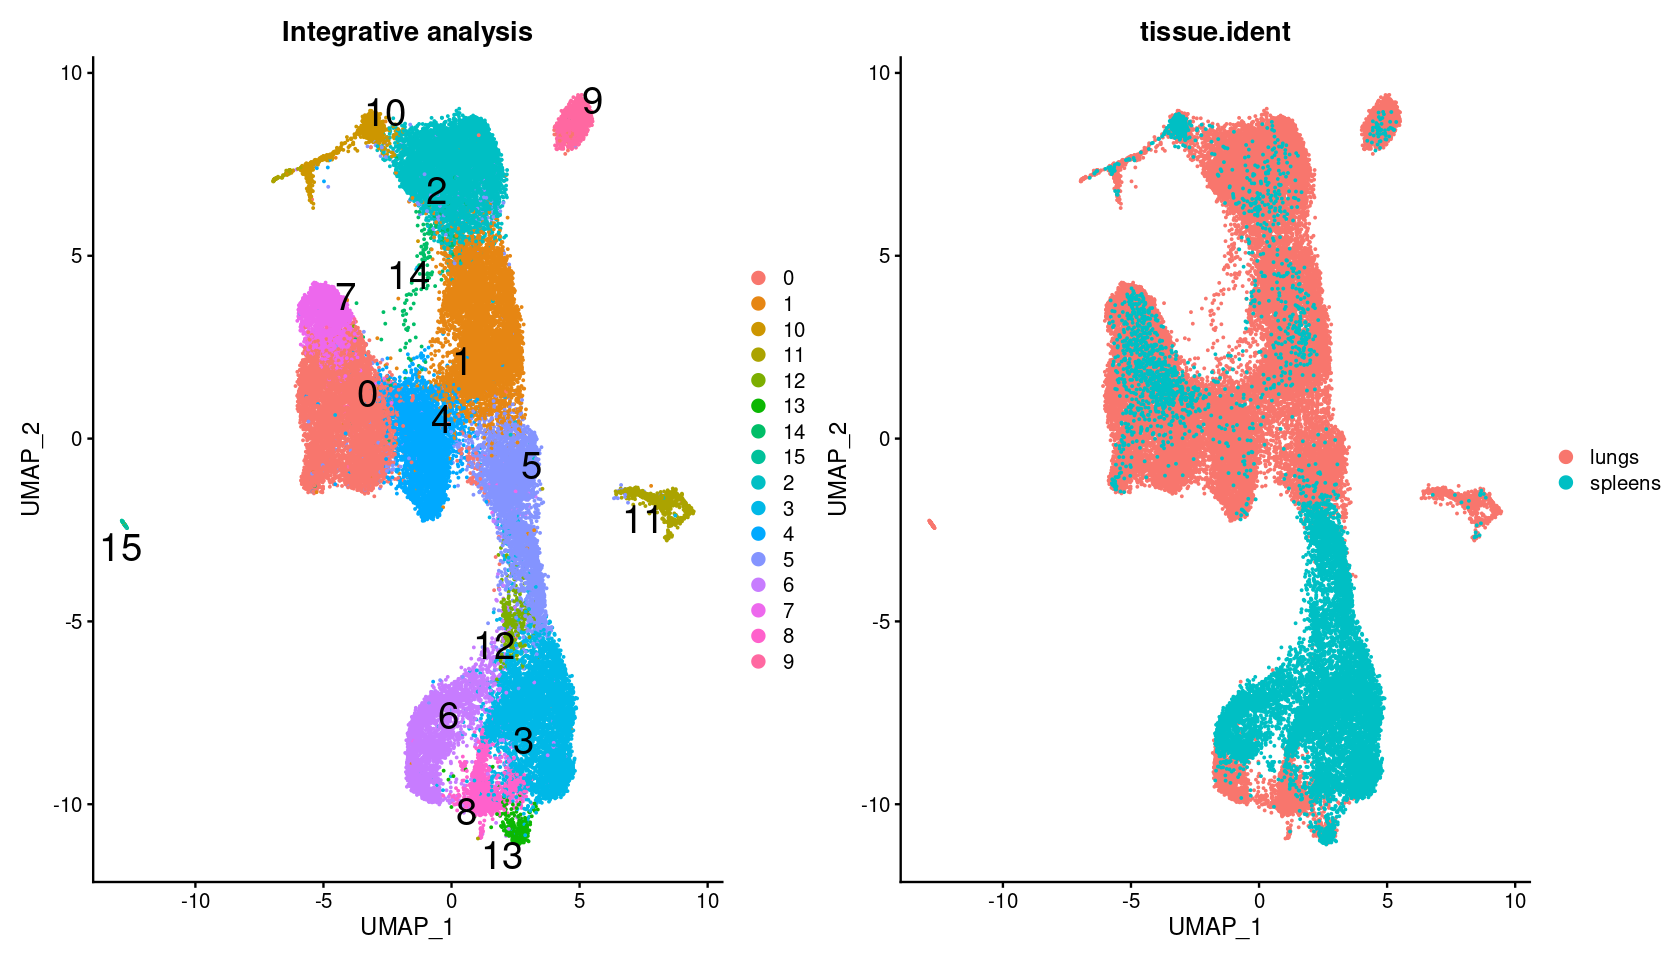

In [8]:
p1<-DimPlot(immune.combined, reduction = "umap", label = TRUE,label.size = 8, repel = TRUE, 
            group.by = 'integrated_snn_res.0.5') + ggtitle("Integrative analysis") 
p2<-DimPlot(immune.combined, reduction = "umap", label = FALSE,label.size = 8, repel = TRUE, group.by = 'tissue.ident') 
p1 + p2  & theme(plot.title = element_text(hjust = 0.5))


In [6]:
immune.combined$CellType <- labels$majority_voting

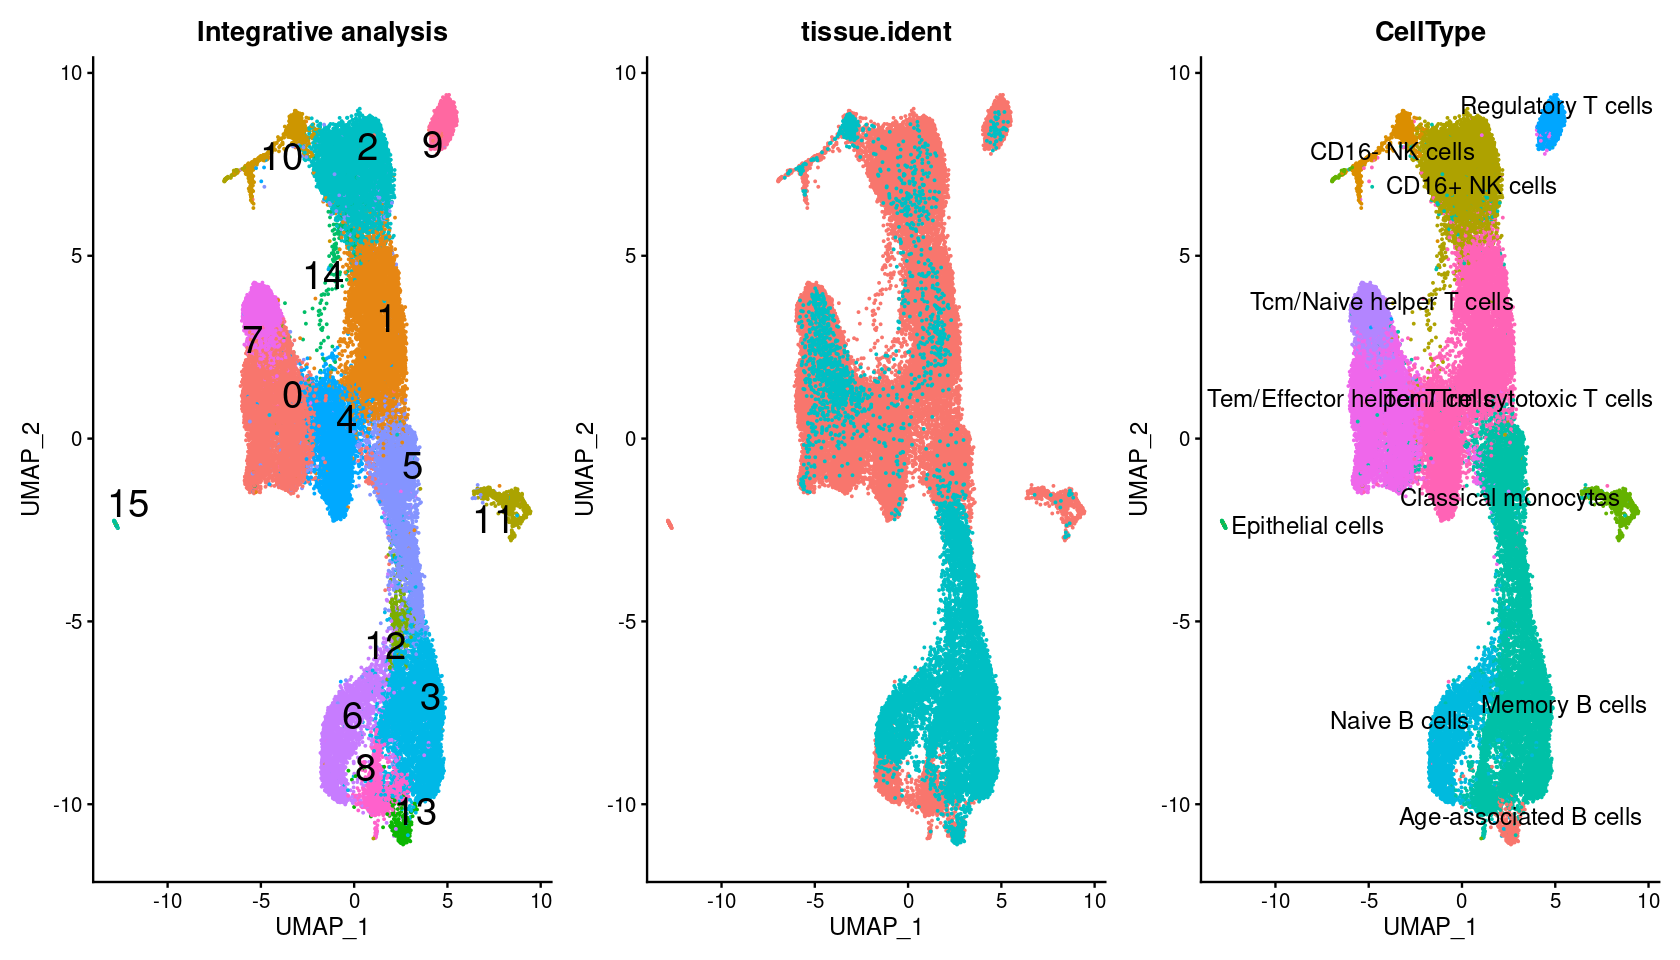

In [36]:
p1 <- DimPlot(immune.combined, reduction = "umap", label = TRUE,label.size = 8, repel = TRUE, 
            group.by = 'integrated_snn_res.0.5') + ggtitle("Integrative analysis") 
p2 <- DimPlot(immune.combined, reduction = "umap", label = FALSE,label.size = 8, repel = TRUE, group.by = 'tissue.ident') 
p3 <- DimPlot(immune.combined, reduction = "umap", label = TRUE,label.size = 5, repel = TRUE, group.by = 'CellType') 
p1 + p2 + p3 & NoLegend() & theme(plot.title = element_text(hjust = 0.5))


In [37]:
jaccard(immune.combined$majority_voting, immune.combined$CellType)
t(sapply(unique(immune.combined$CellType), function(i){
    idx = which(immune.combined$CellType == i)
    return(jaccard(immune.combined$majority_voting[idx], immune.combined$CellType[idx]))
    }))

[1] 3.551400e+04 5.612600e+04 6.327549e-01

CD16+ NK cells,6427,6989,0.9195879
Tem/Effector helper T cells,0,14100,0.0000000
Tem/Trm cytotoxic T cells,10574,12206,0.8662953
Tcm/Naive helper T cells,2121,2209,0.9601630
Memory B cells,11351,12479,0.9096081
CD16- NK cells,623,1451,0.4293591
Naive B cells,2490,3938,0.6323007
Regulatory T cells,1068,1186,0.9005059
Classical monocytes,793,867,0.9146482
Age-associated B cells,0,634,0.0000000
Epithelial cells,67,67,1.0000000


In [12]:
#labels <- fread("../output/predicted_labels_integrated_removeDup.txt")
table(immune.combined@meta.data$majority_voting[immune.combined@meta.data$CellType == "Tem/Effector helper T cells"])


           CD16+ NK cells                      ILC3            Memory B cells 
                        3                        29                        96 
       Regulatory T cells  Tcm/Naive helper T cells Tem/Trm cytotoxic T cells 
                       79                      4307                       207 
   Type 17 helper T cells 
                     2329 

In [9]:
pbmc.markers <- FindAllMarkers(immune.combined, only.pos = TRUE)
pbmc.markers %>%
    group_by(cluster) %>%
    dplyr::filter(avg_log2FC > 1) %>%
    dplyr::filter(!grepl("AC", gene)) %>%
    slice_head(n = 3) %>%
    ungroup() -> top3
pdf("../output/Heatmap_markerGE_integrated_dup_removed.pdf")
DoHeatmap(immune.combined, features = top3$gene) + NoLegend()
dev.off()

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7

Calculating cluster 8

Calculating cluster 9

Calculating cluster 10

Calculating cluster 11

Calculating cluster 12

Calculating cluster 13

Calculating cluster 14

Calculating cluster 15



ERROR: Error in pdf("output/Heatmap_markerGE_integrated_dup_removed.pdf"): cannot open file 'output/Heatmap_markerGE_integrated_dup_removed.pdf'


In [ ]:
## Save Seurat object into a h5Dad object that can be read by scanpy package
DefaultAssay(immune.combined)<-"RNA"

library("SeuratDisk")
SaveH5Seurat(immune.combined, 
             filename = "~/cluster/projects/u19_multiomics/analyses/remove_dup/lungs_spleens_scRNA_only.h5Seurat")
Convert("~/cluster/projects/u19_multiomics/analyses/remove_dup/lungs_spleens_scRNA_only.h5Seurat", dest = "h5ad")

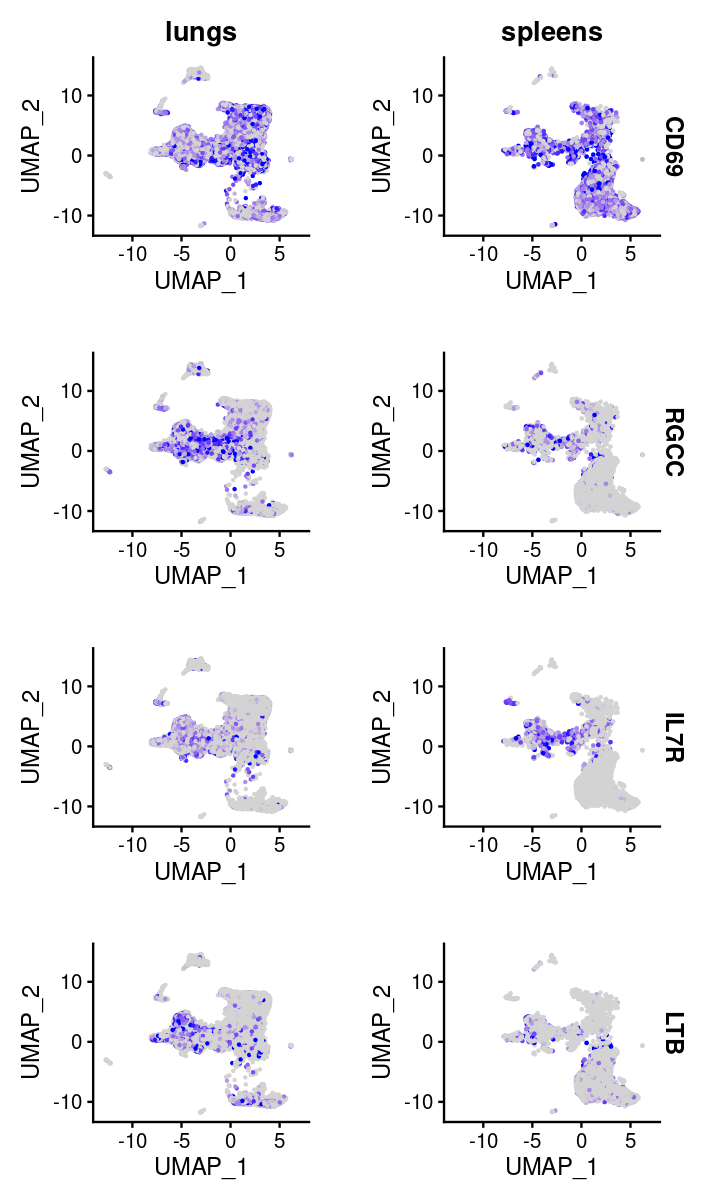

In [33]:
options(repr.plot.width=6, repr.plot.height=10)
DefaultAssay(immune.combined)<-"RNA"
marker.genes<-c("CD69", "RGCC", "CD3D", "MAL",
                "IL7R", "LTB", "NKG7", "GNLY", "PRF1", "MS4A1",
               "CCR7","TCF7", "BANK1", "PAX5")
FeaturePlot(immune.combined, features = marker.genes[1:4], reduction = "umap", 
            split.by = "tissue.ident", min.cutoff = "q10", max.cutoff = "q90")
FeaturePlot(immune.combined, features = marker.genes[5:8], reduction = "umap", 
            split.by = "tissue.ident", min.cutoff = "q10", max.cutoff = "q90")

In [11]:
marker.genes<-c("CD69", "RGCC", "TGFB2", "IL7R", "LTB", "NKG7", "GNLY", "PRF1", "MS4A1",
                "CCR7","TCF7", "LEF1", "BANK1", "PAX5")

In [ ]:
immune.combined$`integrated_snn_res.0.5`

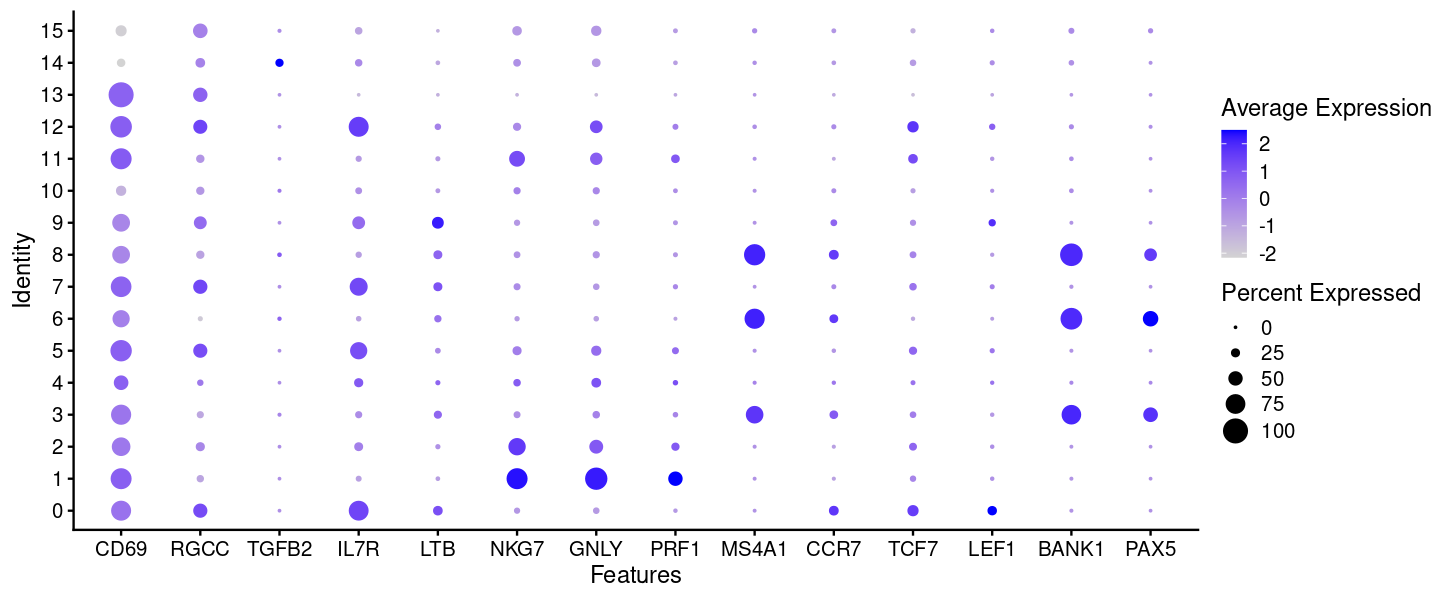

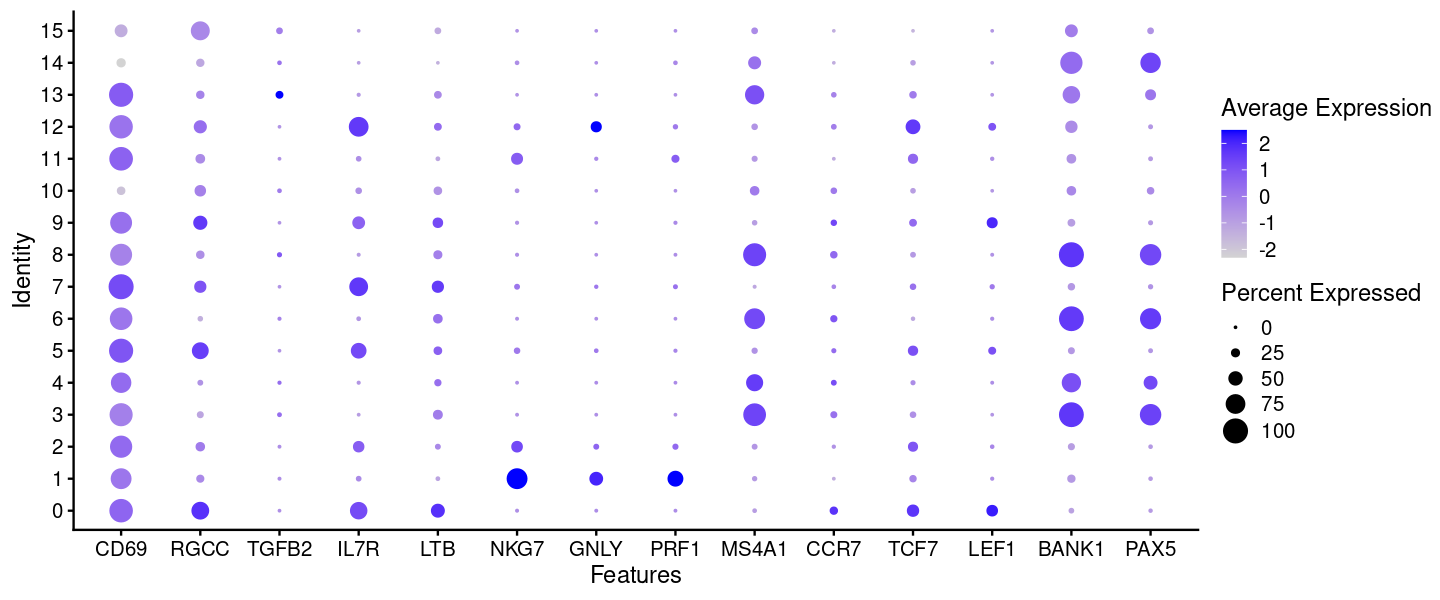

In [12]:
options(repr.plot.width=12, repr.plot.height=5)
DotPlot(subset(immune.combined, tissue.ident == "lungs"), group.by = "integrated_snn_res.0.5", features = marker.genes)
DotPlot(subset(immune.combined, tissue.ident == "spleens"), group.by = "integrated_snn_res.0.5", features = marker.genes)

In [ ]:
pbmc.markers <- FindAllMarkers(immune.combined, only.pos = TRUE)
pbmc.markers %>%
    group_by(cluster) %>%
    dplyr::filter(avg_log2FC > 1) %>%
    dplyr::filter(!grepl("AC", gene)) %>%
    slice_head(n = 3) %>%
    ungroup() -> top3
pdf("output/Heatmap_marker_gene_expression.pdf")
DoHeatmap(immune.combined, features = top3$gene) + NoLegend()
dev.off()

Calculating cluster 0

Warning message:
"`PackageCheck()` was deprecated in SeuratObject 5.0.0.
ℹ Please use `rlang::check_installed()` instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>."
Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7



In [52]:
head(paste(immune.combined$tissue.ident, immune.combined$seurat_clusters, sep = "_"))
new_labels <- as.character(immune.combined$integrated_snn_res.0.5)
new_labels[new_labels == "4"] <- as.character(immune.combined$tissue_integ[immune.combined$integrated_snn_res.0.5 == "4"])

[1] "lungs_9" "lungs_7" "lungs_2" "lungs_2" "lungs_7" "lungs_3"

In [56]:
write.table(new_labels, "../output/integrated_snn_res.0.5_clusters.txt", quote = F, row.names = F)

In [37]:
immune.combined$tissue_integ <- paste(immune.combined$tissue.ident, immune.combined$integrated_snn_res.0.5, sep = "_")

In [38]:
cluster4.spleens <- FindMarkers(immune.combined, group.by = "tissue_integ", ident.1 = "lungs_4", ident.2 = "spleens_4", logfc.threshold = 0.25, test.use = "roc", only.pos = TRUE)

In [39]:
cluster4.lungs <- FindMarkers(immune.combined, group.by = "tissue_integ", ident.1 = "spleens_4", ident.2 = "lungs_4", logfc.threshold = 0.25, test.use = "roc", only.pos = TRUE)

In [47]:
head(cluster4.spleens, 30) #%>% arrange("avg_log2FC", decreasing = TRUE) %>% slice_max(n =10)

,myAUC,avg_diff,power,avg_log2FC,pct.1,pct.2
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
HSP90AA1,0.862,1.4487171,0.724,2.1170122,0.965,0.890
HSPA1A,0.860,2.5333581,0.720,3.8683294,0.815,0.184
DNAJB1,0.804,1.9106540,0.608,2.9915510,0.742,0.305
HSPA1B,0.782,1.4944451,0.564,2.2497412,0.790,0.465
B2M,0.728,1.0567906,0.456,1.5812445,0.787,0.694
SRGN,0.680,1.4743182,0.360,2.4411147,0.520,0.257
ID2,0.674,1.8924018,0.348,3.6996206,0.386,0.047
FYN,0.669,1.4049792,0.338,2.3382986,0.511,0.280
HSPA8,0.666,1.4162450,0.332,2.2948338,0.534,0.344


In [64]:
labels <- read.csv("../output/predicted_labels_integrated_snn_byTissue.txt")
table(labels[grepl("_4", labels$over_clustering),]$majority_voting)


          Memory B cells Tcm/Naive helper T cells 
                    2084                     3564 

In [25]:
write.table(data.frame(rownames(cluster4.markers %>% filter(avg_log2FC > 1.5))), "../output/cluster4_DE_genes.csv", quote = F, row.names = F)

In [15]:
immune.combined$SingleAnnot <- separate$CellType
immune.combined$JointAnnot <- merged$CellType

In [16]:
#options(repr.plot.width=14, repr.plot.height=8)
p1 <- DimPlot(immune.combined, reduction = "umap", group.by = "tissue.ident", label = TRUE, label.size = 4.5, repel = TRUE) + ggtitle("By tissue")
p2 <- DimPlot(immune.combined, reduction = "umap", group.by = "seurat_clusters", label = TRUE, label.size = 4.5, repel = TRUE) + ggtitle("RNA")
p3 <- DimPlot(immune.combined, reduction = "umap", group.by = "PredCellType", label = TRUE, label.size = 4.5, repel = TRUE) + ggtitle("Integrated labels")
p4 <- DimPlot(immune.combined, reduction = "umap", group.by = "SingleAnnot", label = TRUE, label.size = 4.5, repel = TRUE) + ggtitle("Single-tissue labels")
p1 + p2 & NoLegend() & theme(plot.title = element_text(hjust = 0.5))
p3 + p4 & NoLegend() & theme(plot.title = element_text(hjust = 0.5))
#p2 + p3 & NoLegend() & theme(plot.title = element_text(hjust = 0.5))

Warning message:
"The following requested variables were not found: SingleAnnot"


ERROR: Error in `[.data.frame`(data, , group): undefined columns selected


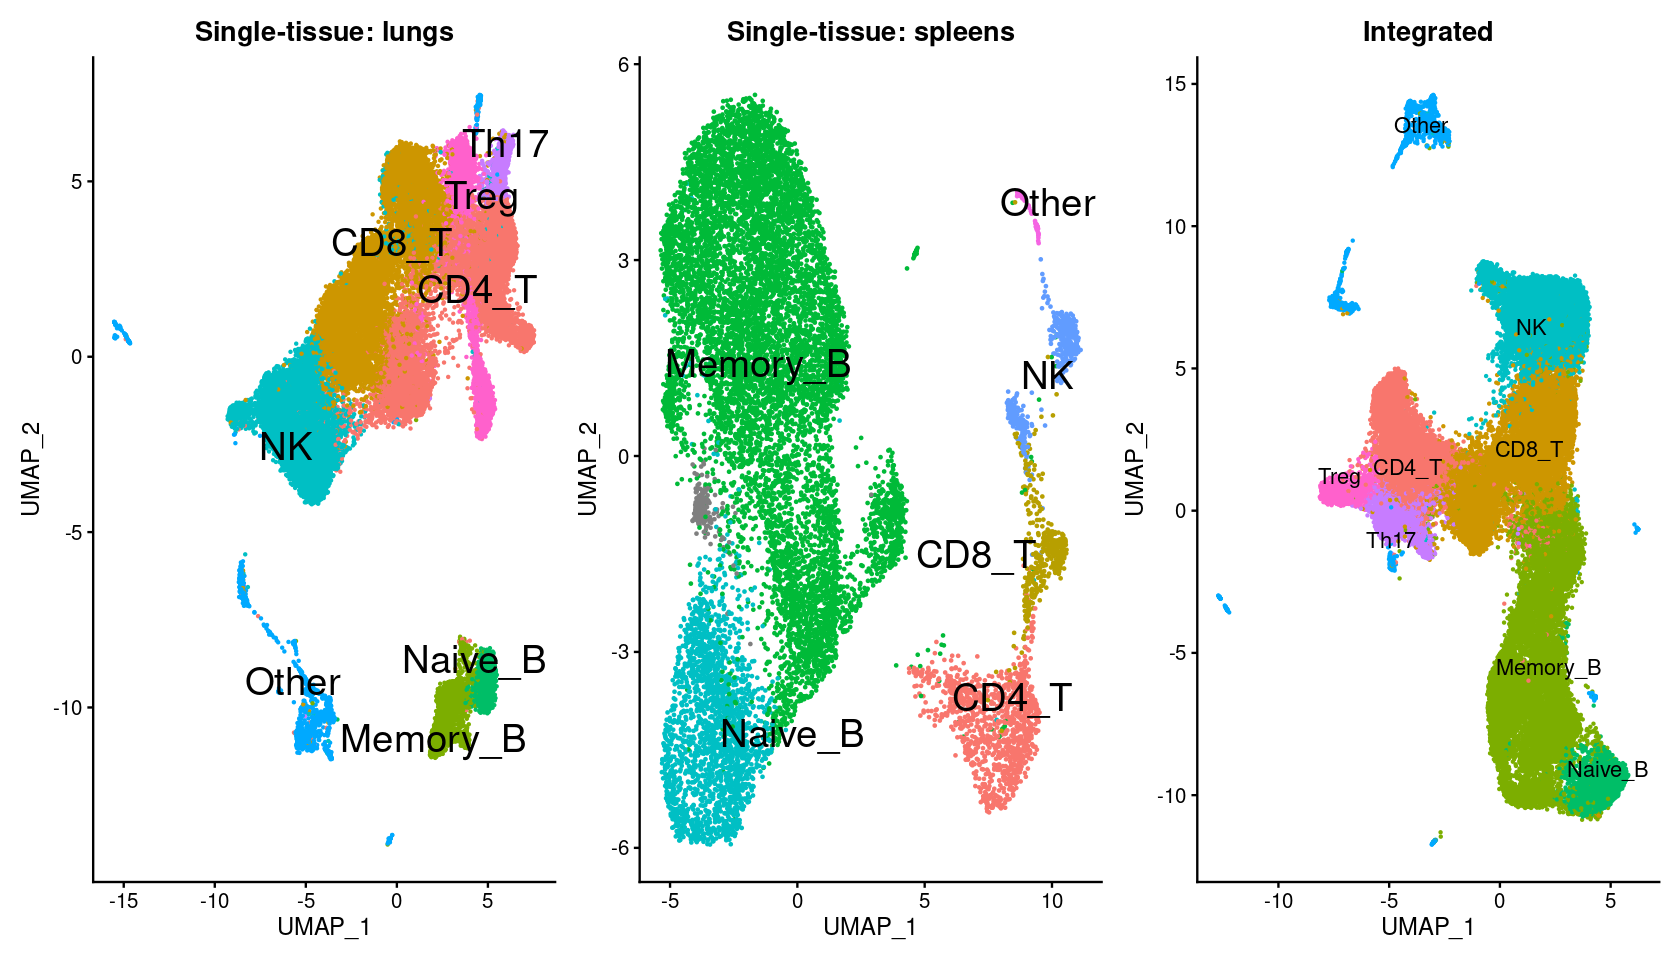

In [31]:
lungs$SingleAnnot <- separate$CellType[separate$Tissue == "lungs"]
spleens$SingleAnnot <- separate$CellType[separate$Tissue == "spleens"]
p1<-DimPlot(lungs, reduction = "umap", label = TRUE,label.size = 8, repel = TRUE, group.by = 'SingleAnnot') + ggtitle("Single-tissue: lungs")
p2<-DimPlot(spleens, reduction = "umap", label = TRUE,label.size = 8, repel = TRUE, group.by = 'SingleAnnot') + ggtitle("Single-tissue: spleens")  
p3 <- DimPlot(immune.combined, reduction = "umap", group.by = "JointAnnot", label = TRUE, label.size = 4.5, repel = TRUE) + ggtitle("Integrated")
p1 + p2 + p3 & NoLegend()  & theme(plot.title = element_text(hjust = 0.5))

In [115]:
cd4t_merge <- rownames(immune.combined@meta.data %>% filter(majority_voting == "Tcm/Naive helper T cells" & tissue.ident == "lungs"))
cd4t_merge <- unlist(lapply(cd4t_merge, function(i){strsplit(i, "_")[[1]][1]}))
cd4t_sep <- rownames(lungs@meta.data %>% filter(majority_voting == "Tcm/Naive helper T cells"))

In [117]:
immune.combined$Barcode <- rownames(immune.combined@meta.data)
cd4t <- subset(immune.combined, Barcode %in% paste0(setdiff(cd4t_sep, cd4t_merge), "_1"))

In [ ]:
marker.genes<-c("RORC","CCR6",
                "CD8A","IFNG", "IGHM",
                "CCR7","BANK1","MS4A1",
                "CD4", "FOXP3",
                "TBX21","GATA3",
                "BCL6"
                )
FeaturePlot(immune.combined, features = marker.genes)

In [46]:
merged_meta <- immune.combined@meta.data
#write.table(merged_meta, "../data/all_lungs_spleens_metadata", quote = F, row.names = T, sep = ",")

In [95]:
# Using Jaccard similarity index to assess how similar are the results of two approaches 
similarity_tbl <-
    t(sapply(unique(merged$CellType), function(i) {
        barcodes = merged$Barcode[merged$CellType== i]
        print(sprintf("%s, %s", i, length(barcodes)))
        merged_ct = merged$CellType[match(barcodes, merged$Barcode)]
        separate_ct = separate$CellType[match(barcodes, separate$Barcode)]
        return(jaccard(separate_ct, merged_ct))
        }))

[1] "Memory_B, 15794"
[1] "NK, 8531"
[1] "CD4_T, 7866"
[1] "CD8_T, 12631"
[1] "Th17, 2800"
[1] "Other, 1758"
[1] "Naive_B, 2884"
[1] "Treg, 1383"


In [91]:
print(sprintf("Overall similarity score: %s", jaccard(merged$CellType, separate$CellType)))

[1] "Overall similarity score: 44708"            
[2] "Overall similarity score: 62586"            
[3] "Overall similarity score: 0.714345061195795"


In [100]:
data.frame(table(separate$CellType[match(barcodes, separate$Barcode)]))

Var1,Freq
<fct>,<int>
CD4_T,3322
CD8_T,212
Memory_B,11195
Naive_B,722
NK,86
Other,19
Th17,5
Treg,61


In [113]:
barcodes = merged$Barcode[merged$CellType == "Th17"]
separate %>% 
    filter(Barcode %in% barcodes & CellType != "Th17") %>% 
    group_by(CellType) %>% summarise(n = n())

CellType,n
<chr>,<int>
CD4_T,233
CD8_T,114
Memory_B,7
NK,10
Naive_B,1
Other,8
Treg,1560


In [59]:
write.table(data.frame(similarity_tbl), col.names = c("Num_common", "Num_union", "Score"),  
            "../output/similarity_table.csv", quote = F, sep = ",")

In [32]:
lungs_wnn <- readRDS("~/cluster/projects/u19_multiomics/AGG_lungs/all_lungs_multi_WNN_zscore.rds")
lungs_clusters<-read.csv("~/cluster/projects//u19_multiomics/AGG_lungs/all_lungs_multi_WNN_immune_low_labels.csv")
lungs_wnn@meta.data$majority_voting <- lungs_clusters$majority_voting

spleens_wnn <- readRDS("~/cluster/projects/u19_multiomics/AGG_spleens/all_spleens_multi_WNN.rds")
spleens_clusters<-read.csv("~/cluster/projects/u19_multiomics/AGG_spleens/all_spleens_wnn_scaling_Immune_low_labels.csv")
spleens_wnn@meta.data$majority_voting <- spleens_clusters$majority_voting

In [21]:
table(lungs@meta.data$integrated_snn_res.0.5)


   0    1    2    3    4    5    6    7    8    9   10   11   12   13   14   15 
7081 6941 5922 5151 3846 1855 1810 1417 1164 1025  938  744  474  409  393  125 
  16   17 
  89   56 

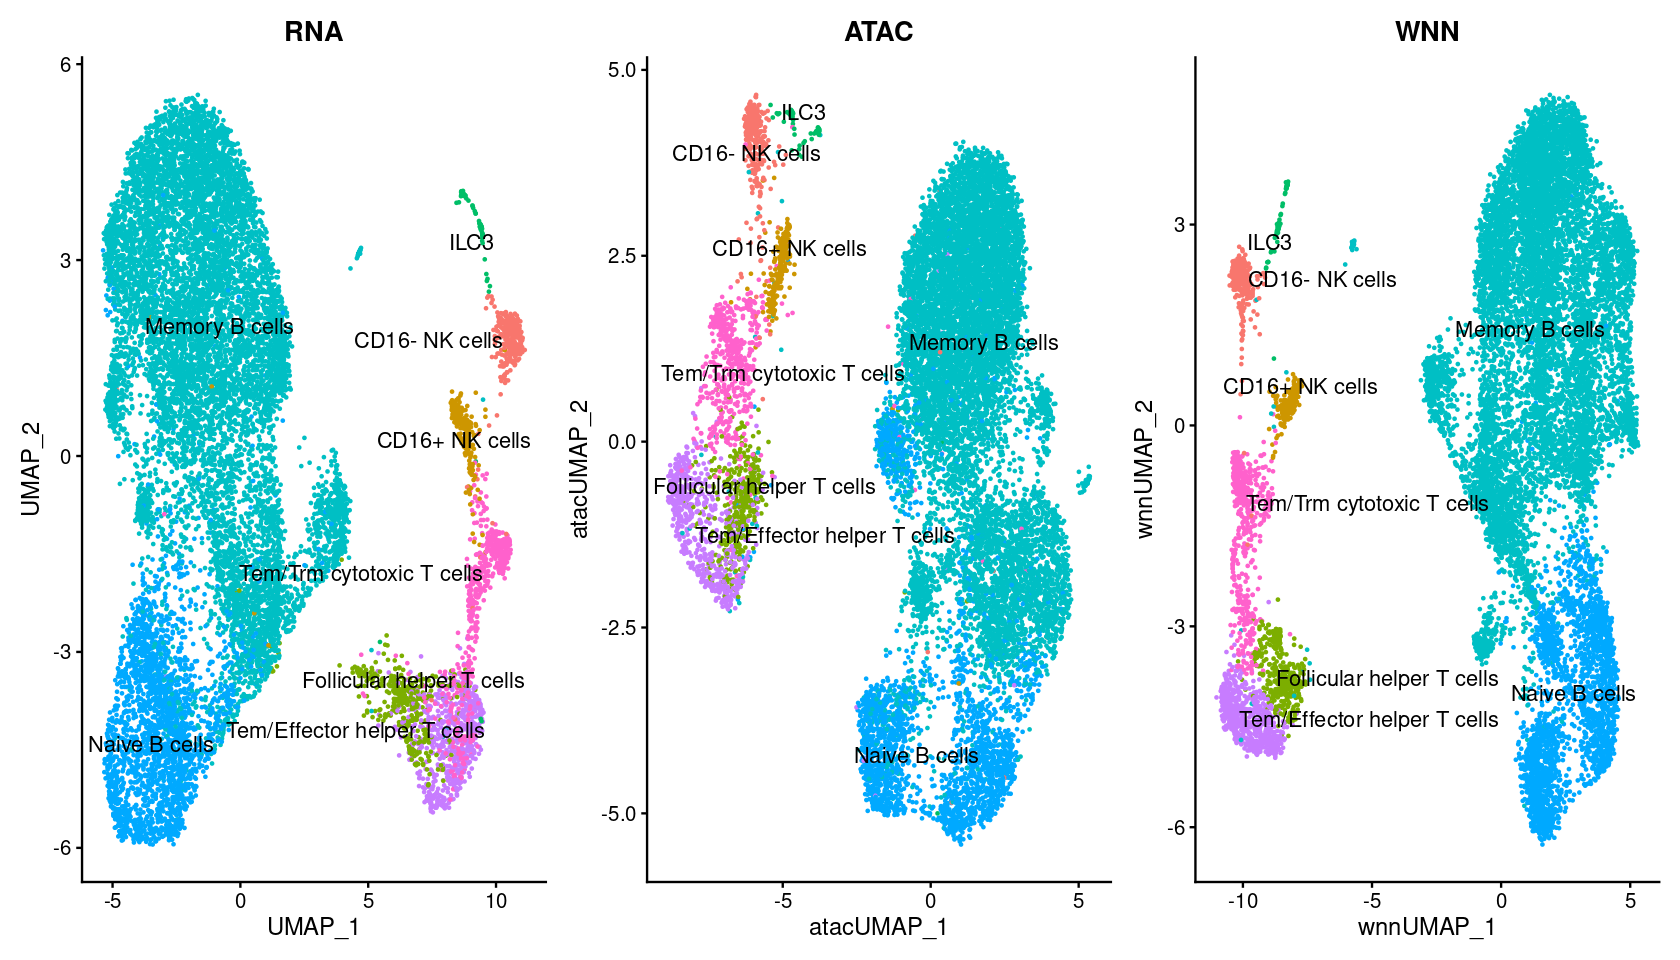

In [33]:
options(repr.plot.width=14, repr.plot.height=8)
p1 <- DimPlot(spleens, reduction = "umap", group.by = "SingleAnnot", label = TRUE, label.size = 4.5, repel = TRUE) + ggtitle("RNA")
p2 <- DimPlot(spleens_wnn, reduction = "umap.atac", group.by = "majority_voting", label = TRUE, label.size = 4.5, repel = TRUE) + ggtitle("ATAC")
p3 <- DimPlot(spleens_wnn, reduction = "wnn.umap", group.by = "majority_voting", label = TRUE, label.size = 4.5, repel = TRUE) + ggtitle("WNN")
p1 + p2 + p3 & NoLegend() & theme(plot.title = element_text(hjust = 0.5))
#p2 + p3 & NoLegend() & theme(plot.title = element_text(hjust = 0.5))

In [17]:
spleens_list <- split(spleens@meta.data, spleens@meta.data$majority_voting)
meta = spleens_wnn@meta.data

t(sapply(spleens_list, function(i){
    query_ct = meta$majority_voting[match(rownames(i), rownames(meta))]
    ref_ct = i$majority_voting
    return(jaccard(query_ct, ref_ct))
    }))

Age-associated B cells,0,348,0.0000000
CD16- NK cells,286,316,0.9050633
CD16+ NK cells,167,169,0.9881657
ILC3,50,50,1.0000000
Memory B cells,9350,9964,0.9383782
Naive B cells,2141,2373,0.9022335
Tcm/Naive helper T cells,0,2318,0.0000000
Tem/Trm cytotoxic T cells,380,502,0.7569721


In [34]:
spleens_list <- merged_meta %>% filter(tissue.ident == "spleens")
spleens_list <- split(spleens_list, spleens_list$majority_voting)
meta = spleens_wnn@meta.data

t(sapply(spleens_list, function(i){
    barcodes = unlist(lapply(rownames(i), function(i){strsplit(i, "_")[[1]][1]}))
    query_ct = meta$majority_voting[match(barcodes, rownames(meta))]
    ref_ct = i$majority_voting
    return(jaccard(query_ct, ref_ct))
    }))

CD16- NK cells,239,243,0.9835391
CD16+ NK cells,191,255,0.7490196
Classical monocytes,0,44,0.0000000
Epithelial cells,0,46,0.0000000
ILC3,39,65,0.6000000
Memory B cells,9509,11505,0.8265102
Naive B cells,1618,1802,0.8978912
Plasma cells,0,14,0.0000000
Regulatory T cells,0,94,0.0000000
Tcm/Naive helper T cells,0,1772,0.0000000
Tem/Trm cytotoxic T cells,353,489,0.7218814


In [ ]:
spleens_list <- split(spleens@meta.data, spleens@meta.data$majority_voting)
meta = spleens_wnn@meta.data

t(sapply(spleens_list, function(i){
    query_ct = meta$majority_voting[match(rownames(i), rownames(meta))]
    ref_ct = i$majority_voting
    return(jaccard(query_ct, ref_ct))
    }))

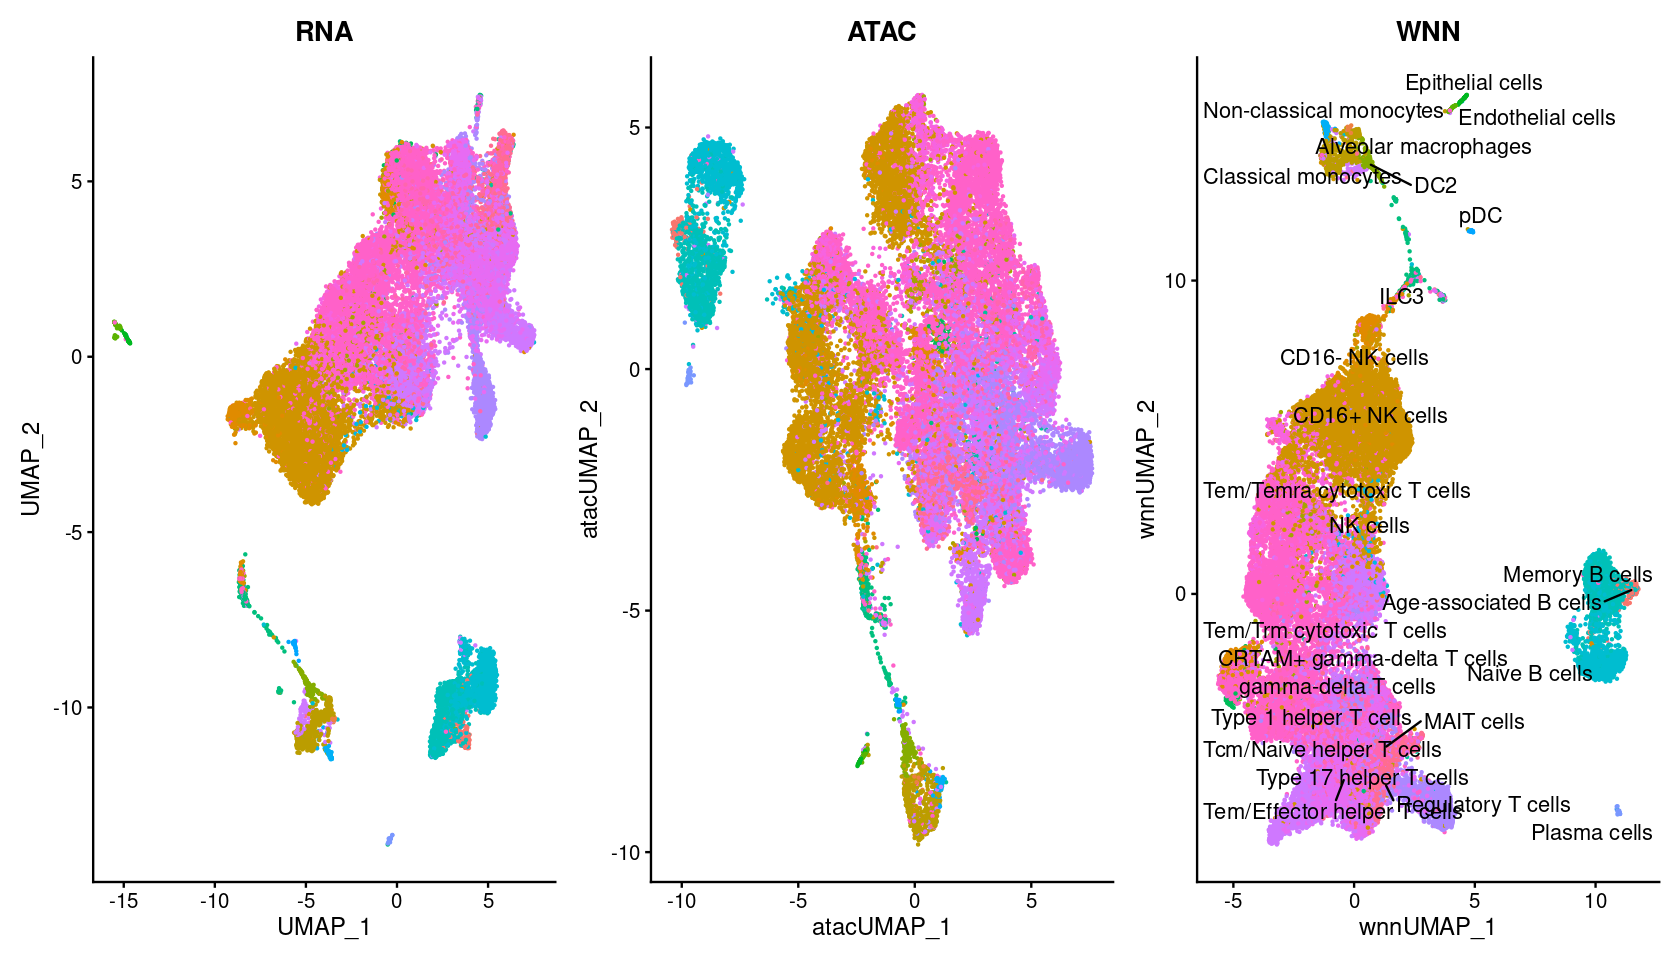

In [35]:
options(repr.plot.width=14, repr.plot.height=8)
p1 <- DimPlot(lungs_wnn, reduction = "umap", group.by = "majority_voting", label = FALSE, label.size = 4.5, repel = TRUE) + ggtitle("RNA")
p2 <- DimPlot(lungs_wnn, reduction = "umap.atac", group.by = "majority_voting", label = FALSE, label.size = 4.5, repel = TRUE) + ggtitle("ATAC")
p3 <- DimPlot(lungs_wnn, reduction = "wnn.umap", group.by = "majority_voting", label = TRUE, label.size = 4.5, repel = TRUE) + ggtitle("WNN")
p4 <- DimPlot(lungs_wnn, reduction = "wnn.umap", label = TRUE, label.size = 4.5, repel = TRUE) + ggtitle("WNN")
p1 + p2 + p3 & NoLegend() & theme(plot.title = element_text(hjust = 0.5))
#p2 + p4 & NoLegend() & theme(plot.title = element_text(hjust = 0.5))

In [35]:
lung.integrated <- lungs_wnn
DefaultAssay(lung.integrated) <- "ATAC"
lung.integrated <- RunTFIDF(lung.integrated)
lung.integrated <- FindTopFeatures(lung.integrated, min.cutoff = 'q0')
lung.integrated <- RunSVD(lung.integrated)

Performing TF-IDF normalization

Running SVD

Scaling cell embeddings

Warning message:
"The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session"
15:08:55 UMAP embedding parameters a = 0.9922 b = 1.112

15:08:55 Read 39440 rows and found 49 numeric columns

15:08:55 Using Annoy for neighbor search, n_neighbors = 30

15:08:55 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:09:01 Writing NN index file to temp file /tmp/jobs/48505681/RtmpPq1D8q/file38650323242f4

15:09:01 Searching Annoy index using 1 thread, search_k = 3000

15:09:18 Annoy recall = 100%

15:09:

In [22]:
lungs_list <- split(lungs_wnn@meta.data, lungs_wnn@meta.data$majority_voting)
separate_meta = lungs@meta.data

t(sapply(lungs_list, function(i){
    separate_ct = separate_meta$majority_voting[match(rownames(i), rownames(separate_meta))]
    merged_ct = i$majority_voting
    return(jaccard(separate_ct, merged_ct))
    }))

Age-associated B cells,0,304,0.0000000
Alveolar macrophages,0,52,0.0000000
CD16- NK cells,398,1456,0.2733516
CD16+ NK cells,6996,9488,0.7373524
Classical monocytes,594,632,0.9398734
CRTAM+ gamma-delta T cells,0,624,0.0000000
DC2,0,296,0.0000000
Endothelial cells,0,84,0.0000000
Epithelial cells,46,48,0.9583333
gamma-delta T cells,0,556,0.0000000
ILC3,356,422,0.8436019


In [16]:
# Comparing lung scRNA labels vs. lung multiome approach
lungs_list <- split(lungs@meta.data, lungs@meta.data$majority_voting)
meta = lungs_wnn@meta.data

t(sapply(lungs_list, function(i){
    query_ct = meta$majority_voting[match(rownames(i), rownames(meta))]
    ref_ct = i$majority_voting
    return(jaccard(query_ct, ref_ct))
    }))

CD16- NK cells,398,550,0.7236364
CD16+ NK cells,6996,8374,0.8354430
Classical monocytes,594,1456,0.4079670
Epithelial cells,46,132,0.3484848
ILC3,356,680,0.5235294
Memory B cells,1322,2388,0.5536013
Naive B cells,1101,1227,0.8973105
Plasma cells,55,57,0.9649123
Regulatory T cells,2047,4407,0.4644883
Tcm/Naive helper T cells,3976,16378,0.2427647
Tem/Trm cytotoxic T cells,8715,15749,0.5533685


Warning message:
"The `slot` argument of `FetchData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>."


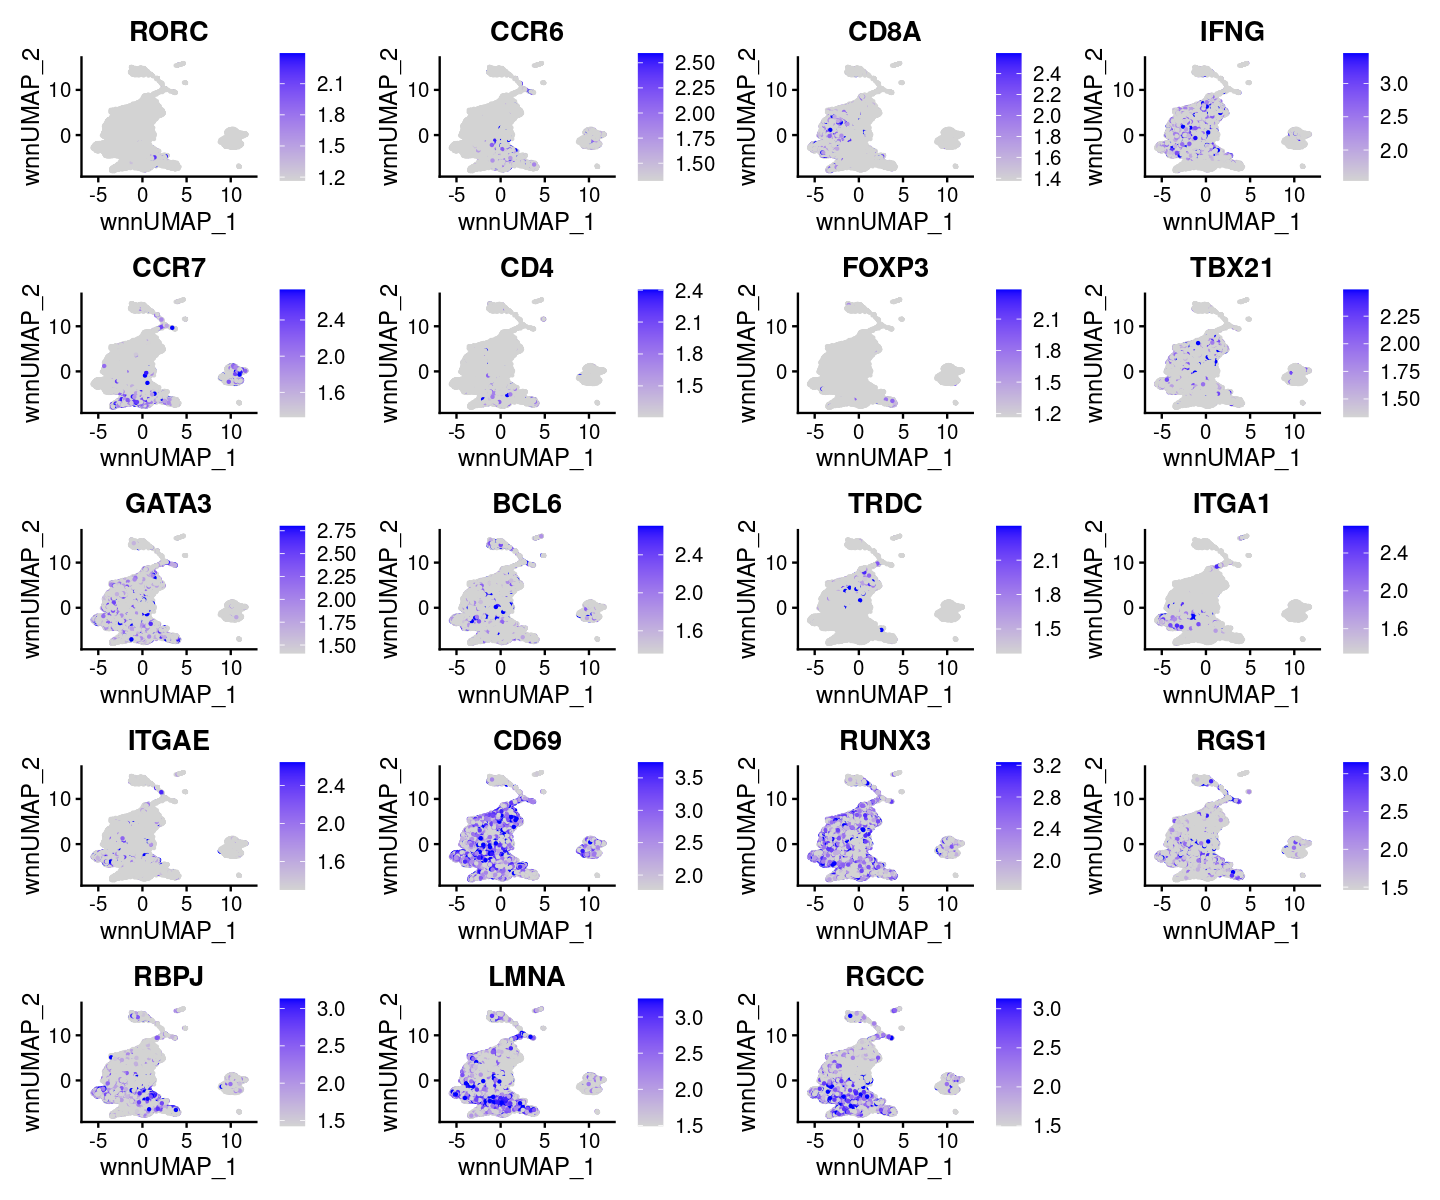

In [23]:
DefaultAssay(lungs_wnn)<-"RNA"
marker.genes<-c("RORC","CCR6",
                "CD8A","IFNG", 
                "CCR7",
                "CD4", "FOXP3",
                "TBX21","GATA3",
                "BCL6","TRDC",
                "ITGA1", "ITGAE", "CD69",
                "RUNX3", "RGS1", "RBPJ","LMNA", "RGCC"
                )
FeaturePlot(lungs_wnn, features = marker.genes, reduction = "wnn.umap", min.cutoff = "q10", max.cutoff = "q90")

## Applying WNN to lung-spleen merged datasets

In [32]:
jaccard <- function(a, b) {
    intersection = sum(a == b, na.rm = TRUE)
    union = length(a) + length(b) - intersection
    return (c(intersection, union, intersection/union))
}

In [3]:
integrated <- readRDS("~/cluster/projects/u19_multiomics/analyses/remove_dup/lungs_spleens_integrated.RDS")

In [5]:
immune.combined <- readRDS("~/cluster/projects/u19_multiomics/analyses/remove_dup/lungs_spleens_integrated_sub_wnn.RDS")
#DefaultAssay(immune.combined) <- "integrated"
#immune.combined <- immune.combined %>% FindVariableFeatures() %>% ScaleData() %>% RunPCA() %>% RunUMAP(dims = 1:50, reduction.name = 'umap.rna', reduction.key = 'rnaUMAP_')

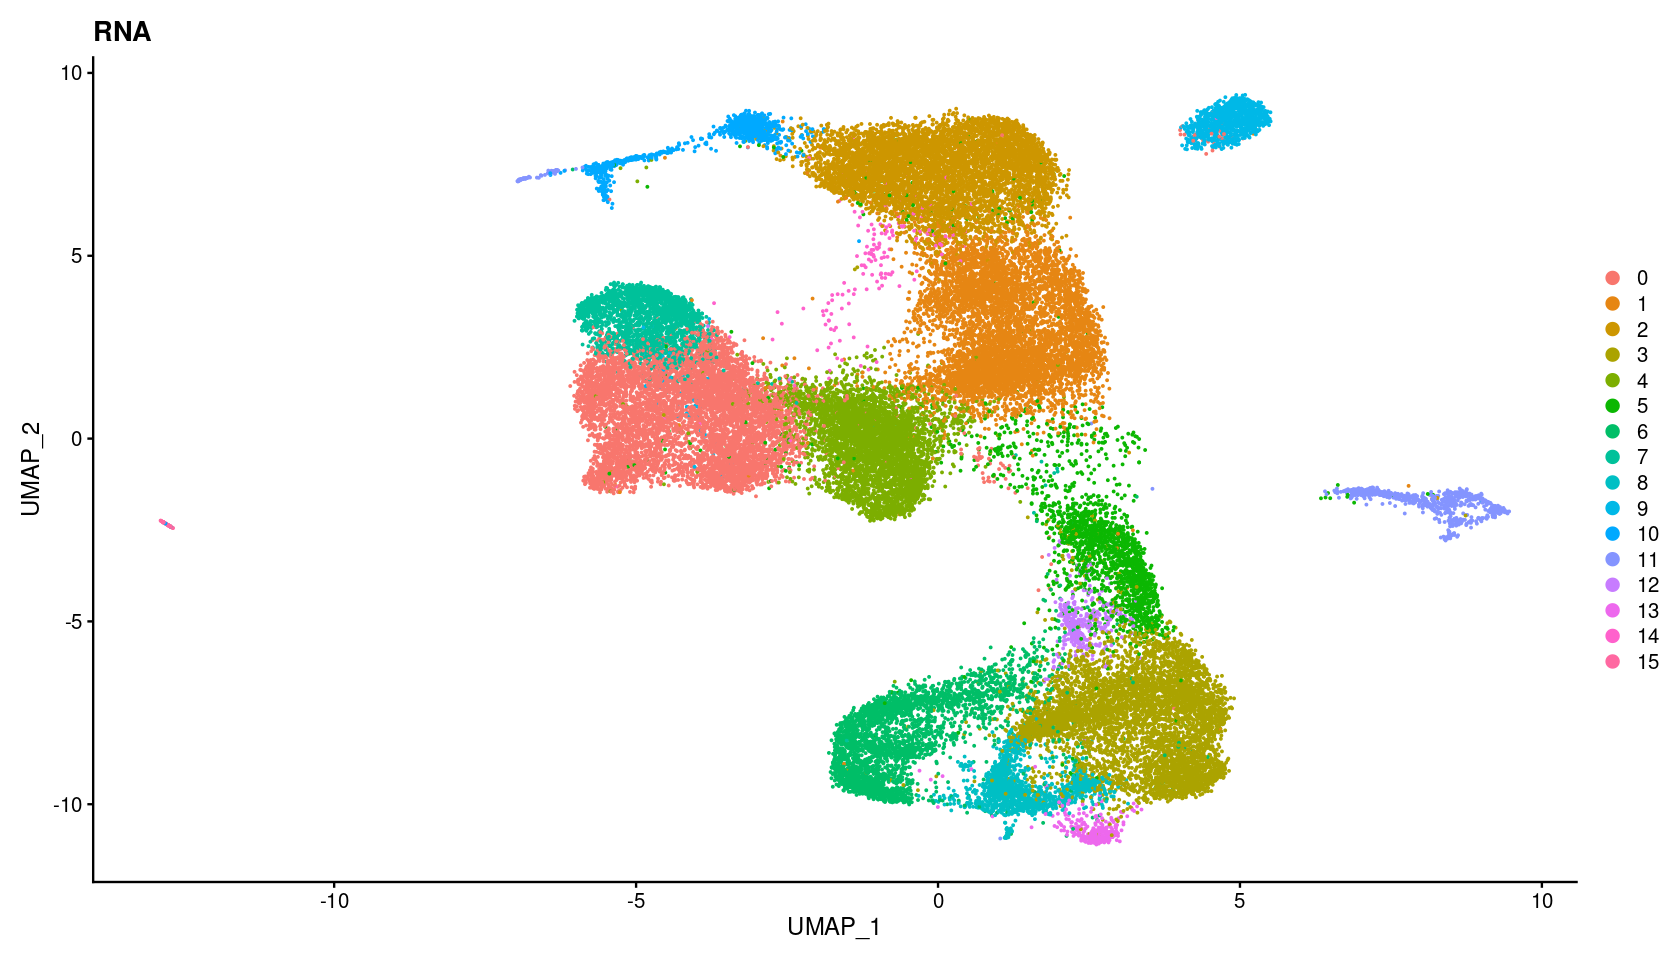

In [16]:
p1 <- DimPlot(immune.combined, reduction = "umap", label = FALSE, label.size = 4.5, repel = TRUE) + ggtitle("RNA")
p1

In [7]:
# perform rPCA on ATAC-seq data
DefaultAssay(immune.combined) <- "ATAC"
atac.list <- SplitObject(immune.combined, split.by = "full.ident")
atac.list <- lapply(X = atac.list, FUN = function(x) {
    x <- RunTFIDF(x)
    x <- FindTopFeatures(x, min.cutoff = 'q0')
    x <- RunSVD(x)
    x <- RunUMAP(x, reduction = 'lsi', dims = 2:50, reduction.name = "umap.atac", reduction.key = "atacUMAP_")
})

Performing TF-IDF normalization

Warning message in RunTFIDF.default(object = GetAssayData(object = object, layer = "counts"), :
"Some features contain 0 total counts"
Running SVD

Scaling cell embeddings

13:49:21 UMAP embedding parameters a = 0.9922 b = 1.112

13:49:21 Read 7700 rows and found 49 numeric columns

13:49:21 Using Annoy for neighbor search, n_neighbors = 30

13:49:21 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

13:49:22 Writing NN index file to temp file /tmp/jobs/48673307/RtmpbKfXvJ/file4aa221943e8f8

13:49:22 Searching Annoy index using 1 thread, search_k = 3000

13:49:24 Annoy recall = 100%

13:49:26 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

13:49:28 Initializing from normalized Laplacian + noise (usi

In [7]:
DefaultAssay(immune.combined) <- "ATAC"
immune.combined <- RunTFIDF(immune.combined)
immune.combined <- FindTopFeatures(immune.combined, min.cutoff = 'q0')
immune.combined <- RunSVD(immune.combined)
immune.combined <- RunUMAP(immune.combined, reduction = 'lsi', dims = 2:50, reduction.name = "umap.atac", reduction.key = "atacUMAP_")

Performing TF-IDF normalization

Running SVD

Scaling cell embeddings

10:49:55 UMAP embedding parameters a = 0.9922 b = 1.112

10:49:55 Read 42863 rows and found 49 numeric columns

10:49:55 Using Annoy for neighbor search, n_neighbors = 30

10:49:55 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

10:50:02 Writing NN index file to temp file /tmp/jobs/48687112/RtmpZokBj0/file383d8473d6117

10:50:02 Searching Annoy index using 1 thread, search_k = 3000

10:50:19 Annoy recall = 100%

10:50:21 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

10:50:25 Initializing from normalized Laplacian + noise (using irlba)

10:50:26 Commencing optimization for 200 epochs, with 1812890 positive edges

10:50:26 Using rng type: pcg

10:51:20 Optimi

In [25]:
#immune.combined <- FindMultiModalNeighbors(immune.combined, reduction.list = list("pca", "lsi"), dims.list = list(1:50, 2:50))
#immune.combined <- RunUMAP(immune.combined, nn.name = "weighted.nn", reduction.name = "wnn.umap", reduction.key = "wnnUMAP_")
immune.combined <- FindClusters(immune.combined, graph.name = "wsnn", algorithm = 3, resolution = 0.2, verbose = FALSE)

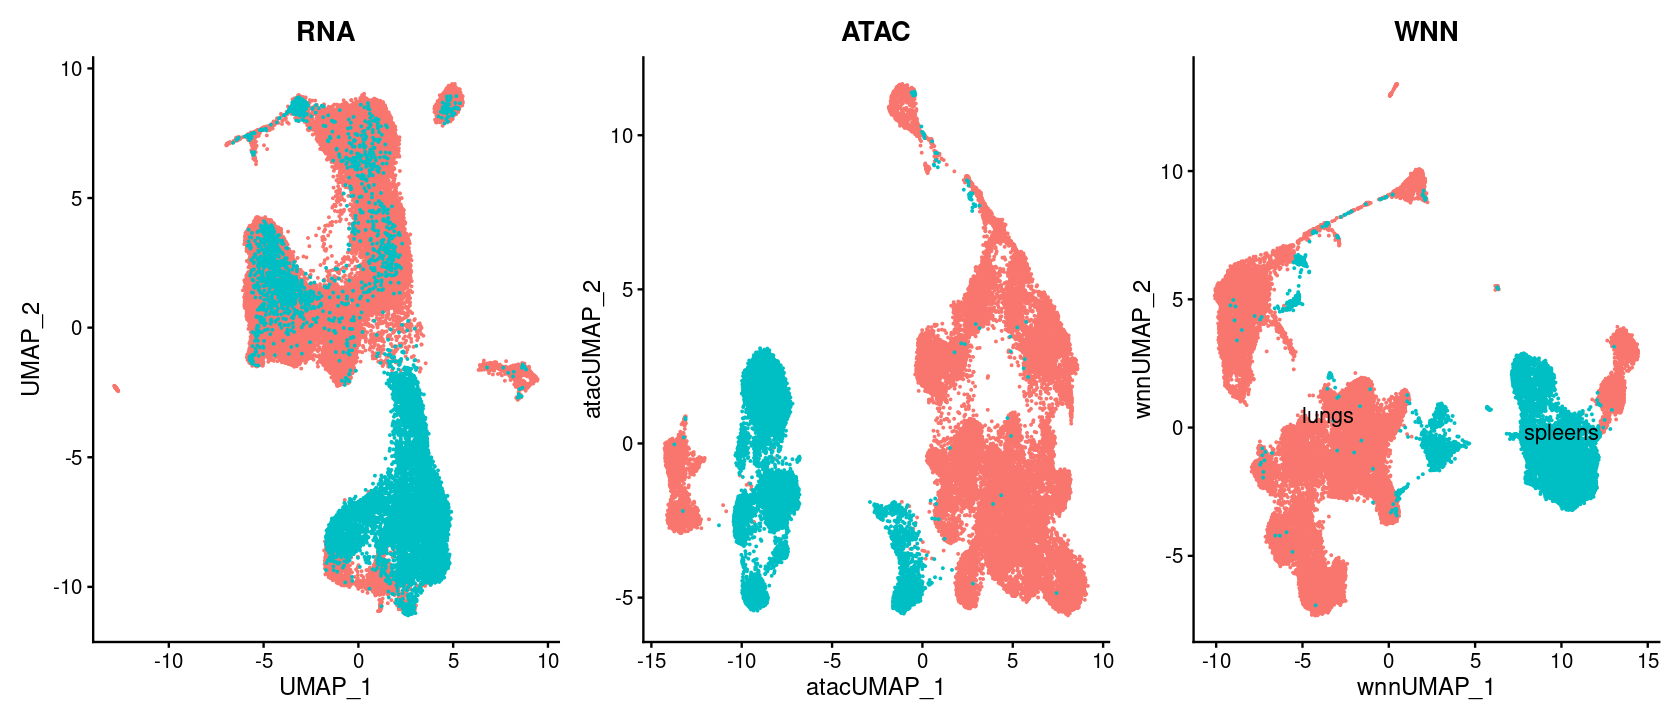

In [20]:
options(repr.plot.width=14, repr.plot.height=6)
p1 <- DimPlot(immune.combined, reduction = "umap", group.by = "tissue.ident", label = FALSE, label.size = 4.5, repel = TRUE) + ggtitle("RNA")
p2 <- DimPlot(immune.combined, reduction = "umap.atac", group.by = "tissue.ident", label = FALSE, label.size = 4.5, repel = TRUE) + ggtitle("ATAC")
p3 <- DimPlot(immune.combined, reduction = "wnn.umap", group.by = "tissue.ident", label = TRUE, label.size = 4.5, repel = TRUE) + ggtitle("WNN")
p4 <- DimPlot(lungs_wnn, reduction = "wnn.umap", label = TRUE, label.size = 4.5, repel = TRUE) + ggtitle("WNN")
p1 + p2 + p3 & NoLegend() & theme(plot.title = element_text(hjust = 0.5))


In [6]:
## cell type annotations
annot <- read.csv("../../output/predicted_labels_integrated_removeDup_wnn.txt")
immune.combined$wnnMajorityVoting <- annot$majority_voting[match(rownames(immune.combined@meta.data), annot$X)]
immune.combined$wnnCellType <- 
    factor(immune.combined$wnnMajorityVoting, 
           labels = c("NK","NK","Other","Other",
                      "Other","Other","Memory_B",
                      "Naive_B","Treg","naiCD4_T","CD8_T"))

In [7]:
integrated <- readRDS("../../output/output_dir/remove_dup/lungs_spleens_integrated_sub.RDS")

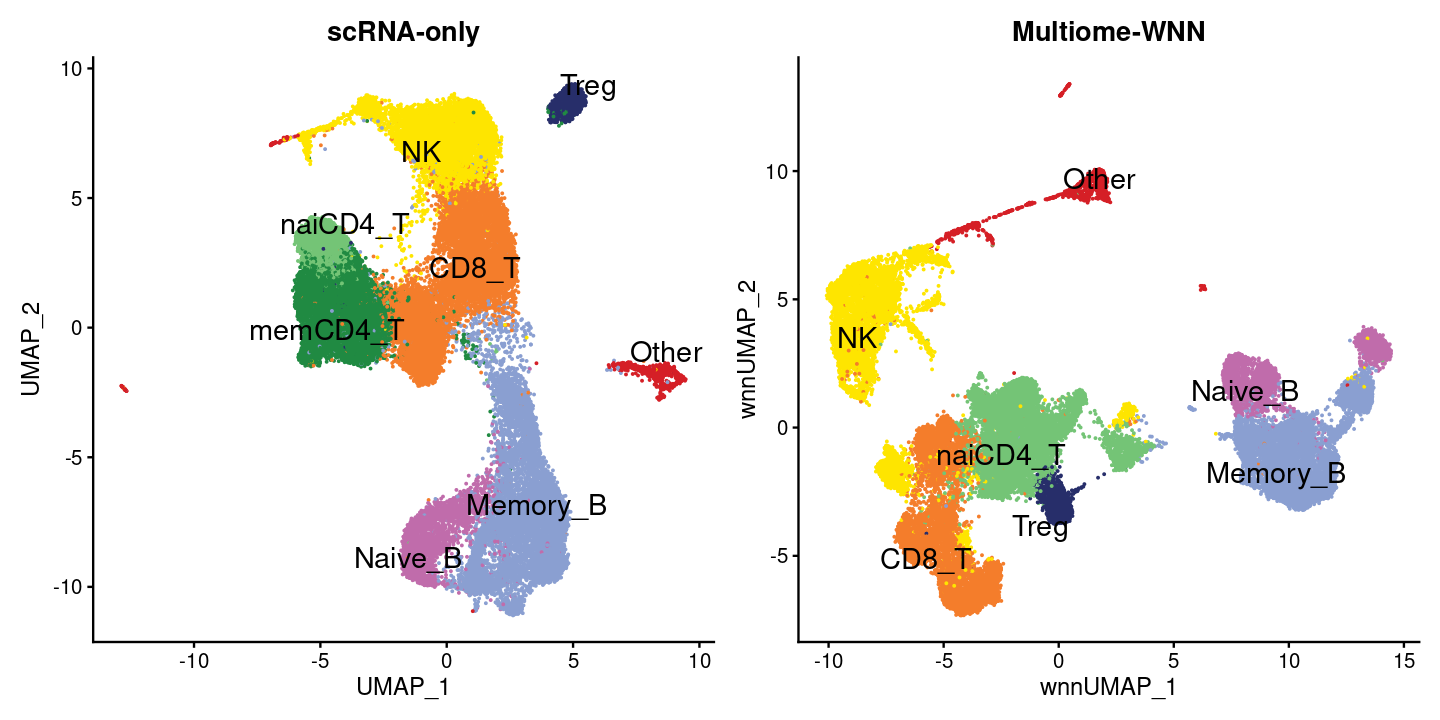

In [17]:
options(repr.plot.width=12, repr.plot.height=6)
p1 <- DimPlot(immune.combined, reduction = "wnn.umap",  group.by = "wnnCellType", cols = pal_rna, 
              label = TRUE, label.size = 6, repel = TRUE) + ggtitle("Multiome-WNN")
p2 <- DimPlot(integrated, reduction = "umap", group.by = "CellType", cols = pal_rna, 
              label = TRUE, label.size = 6, repel = TRUE) + ggtitle("scRNA-only")
p2 + p1 & NoLegend()
#(p1 & NoLegend()) + (p2 + theme(legend.text = element_text(size = 15)))

In [18]:
ggsave(p2 + p1 & NoLegend(), filename = "../../output/plots/wwn_vs_integrated.pdf", height = 6, width = 12)

In [38]:
sim_metrics <-
t(sapply(levels(immune.combined$CellType),function(i) {
    ct_vector = as.character(immune.combined$CellType)
    jaccard(ct_vector[ct_vector == i], 
            as.character(immune.combined$wnnCellType)[ct_vector == i])
    }))
sim_metrics <- data.frame(
    CellType = rownames(sim_metrics),
    Score = sim_metrics[, 3])


In [53]:
p3 <- 
ggplot(sim_metrics %>%
        mutate(CellType = factor(CellType, levels = ct_order)),
        aes(x = CellType,
            y = Score)) + 
geom_col(width = 0.5) + 
theme_pub(base_size  = 15) + 
xlab("")

In [ ]:
save(p1, p2, p3, file = "../../output/plots/FigureL3.RData")

In [39]:
metadata <- data.frame(X = rownames(immune.combined@meta.data),
                       prior_labels = immune.combined$majority_voting)
annot <- left_join(annot, metadata, by = "X")

In [45]:
write.table(immune.combined$`wsnn_res.0.2`, "../output/wsnn_res_0.2_clusters.txt", quote = F, row.names = F)

In [17]:
DefaultAssay(immune.combined) <- "ATAC"
ifnb.list <- SplitObject(immune.combined, split.by = "tissue.ident")
immune.anchors <- FindIntegrationAnchors(object.list = ifnb.list, anchor.features = features, reduction = "rpca")

Assay data with 36601 features for 53647 cells
Top 10 variable features:
 IGHA1, IGKC, SGCZ, SFTPB, JCHAIN, CCL20, IGHG1, IGLC2, SCGB1A1, CCL4L2 

In [15]:
annot <- read.csv("../output/predicted_labels_wsnn.txt")

In [54]:
immune.combined$wsnn_MajorityVoting <- annot$majority_voting

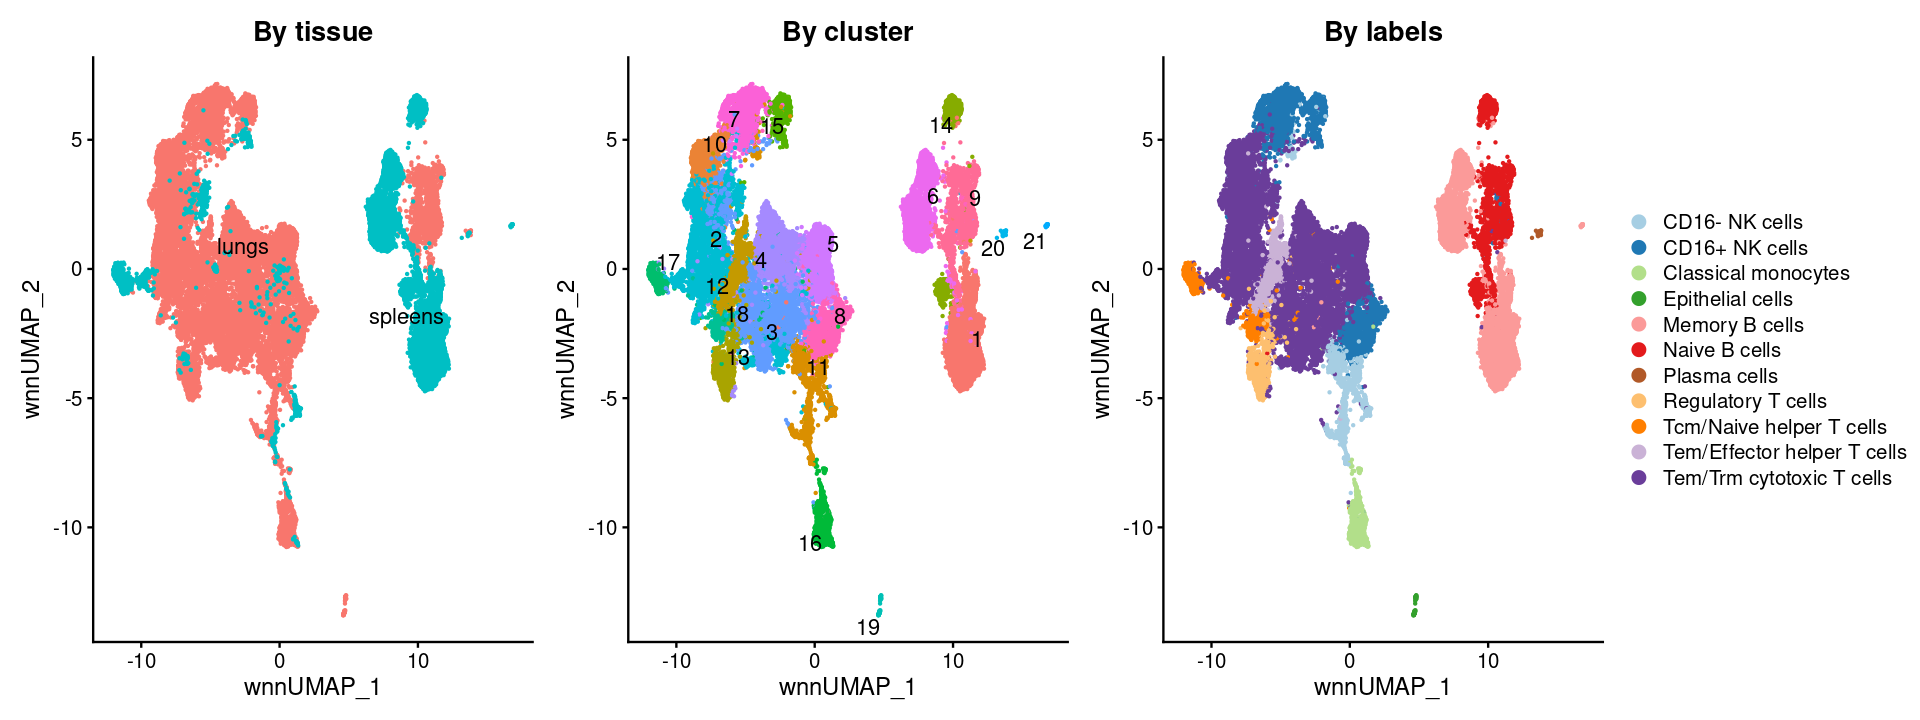

In [15]:
options(repr.plot.width=16, repr.plot.height=6)
pal_integrated <- c('#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c','#b15928','#fdbf6f','#ff7f00','#cab2d6','#6a3d9a')
p1 <- DimPlot(immune.combined, reduction = "wnn.umap", group.by = "tissue.ident", label = TRUE, label.size = 4.5, repel = TRUE) + ggtitle("By tissue") + NoLegend()
p2 <- DimPlot(immune.combined, reduction = "wnn.umap", group.by = "wsnn_res.0.2", label = TRUE, label.size = 4.5, repel = TRUE) + ggtitle("By cluster") + NoLegend()
p3 <- DimPlot(immune.combined, reduction = "wnn.umap", group.by = "wsnn_MajorityVoting", 
              label = FALSE, label.size = 4.5, repel = TRUE, 
              cols = pal_integrated) + ggtitle("By labels")
p4 <- DimPlot(lungs_wnn, reduction = "wnn.umap", group.by = "seurat_clusters", label = TRUE, label.size = 4.5, repel = TRUE) + ggtitle("WNN")
p1 + p2 + p3 & theme(plot.title = element_text(hjust = 0.5))


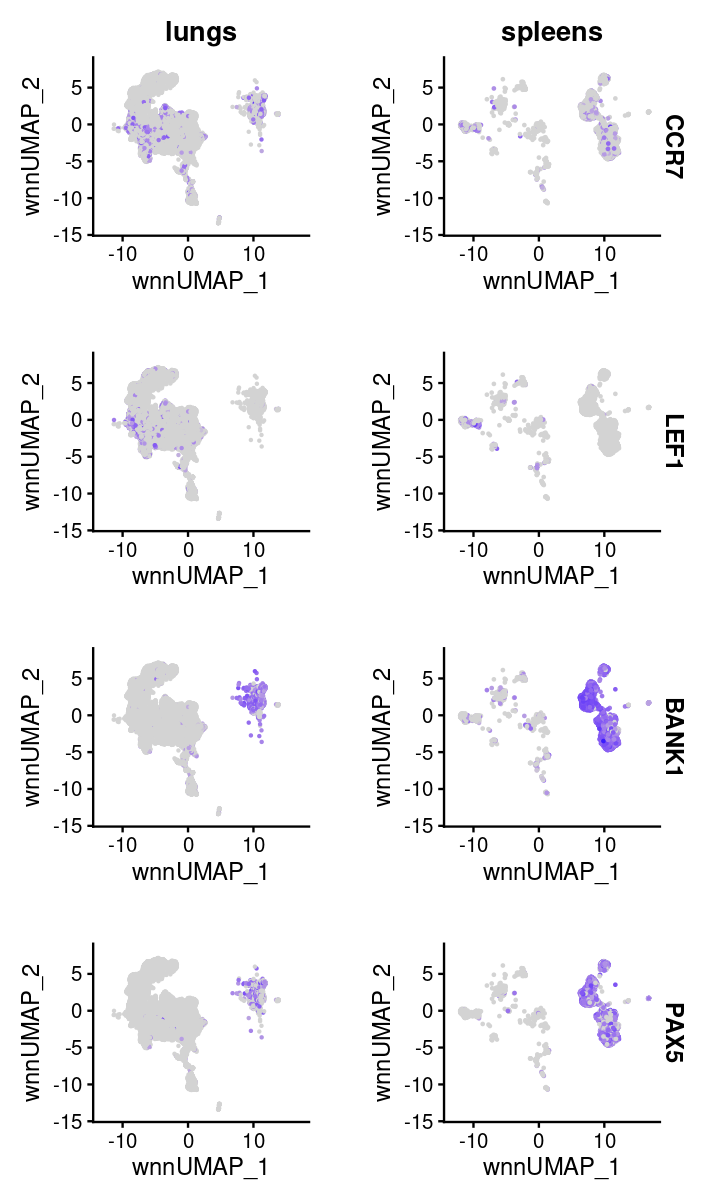

In [32]:
options(repr.plot.width=6, repr.plot.height=10)
marker.genes<-c("CD69", "CD8A",
                "IL7R", "LTB", 
               "CCR7","LEF1", "BANK1", "PAX5")
FeaturePlot(immune.combined, reduction = "wnn.umap", split.by = "tissue.ident", features = marker.genes[5:8])

In [58]:
saveRDS(immune.combined, "~/cluster/projects/u19_multiomics/analyses/lungs_spleens_WNN_processed.rds")

In [16]:
unique(immune.combined$majority_voting)

[1] "Memory B cells"            "CD16+ NK cells"           
 [3] "Tcm/Naive helper T cells"  "Tem/Trm cytotoxic T cells"
 [5] "Type 17 helper T cells"    "ILC3"                     
 [7] "Plasma cells"              "Naive B cells"            
 [9] "Regulatory T cells"        "Classical monocytes"      
[11] "CD16- NK cells"            "Epithelial cells"

In [18]:
## Compared with rPCA integrative approach
print(sprintf("Overall similarity score: %s", jaccard(immune.combined$majority_voting, immune.combined$wsnn_MajorityVoting)))

t(sapply(unique(immune.combined$majority_voting), function(i){
    idx = which(immune.combined$majority_voting == i)
    return(jaccard(immune.combined$majority_voting[idx], immune.combined$wsnn_MajorityVoting[idx]))
    }))

[1] "Overall similarity score: 33093"            
[2] "Overall similarity score: 74201"            
[3] "Overall similarity score: 0.445991293917872"


Memory B cells,9341,22247,0.4198768
CD16+ NK cells,6263,9259,0.6764229
Tcm/Naive helper T cells,1319,14413,0.0915146
Tem/Trm cytotoxic T cells,11382,13880,0.8200288
Type 17 helper T cells,0,5600,0.0000000
ILC3,0,1102,0.0000000
Plasma cells,62,62,1.0000000
Naive B cells,1679,4089,0.4106138
Regulatory T cells,1257,1509,0.8330020
Classical monocytes,1024,1040,0.9846154
CD16- NK cells,676,864,0.7824074


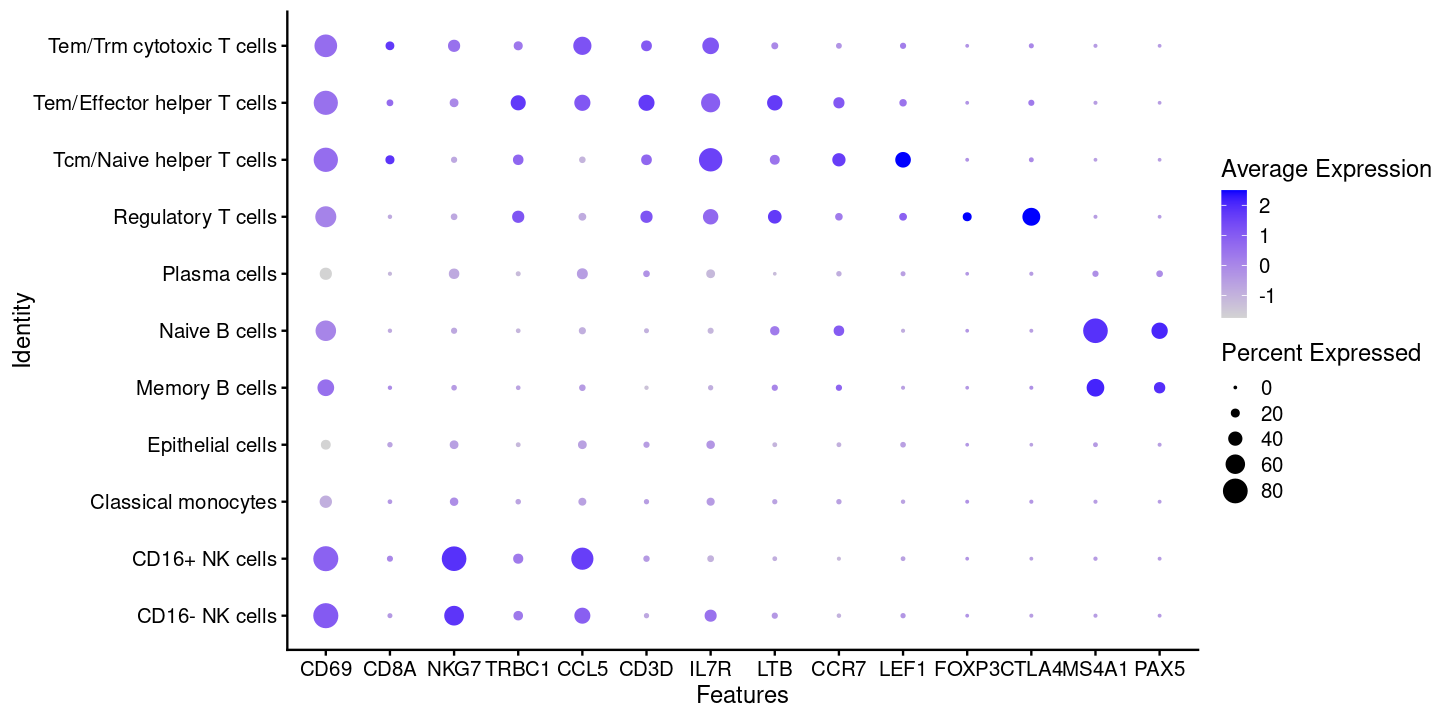

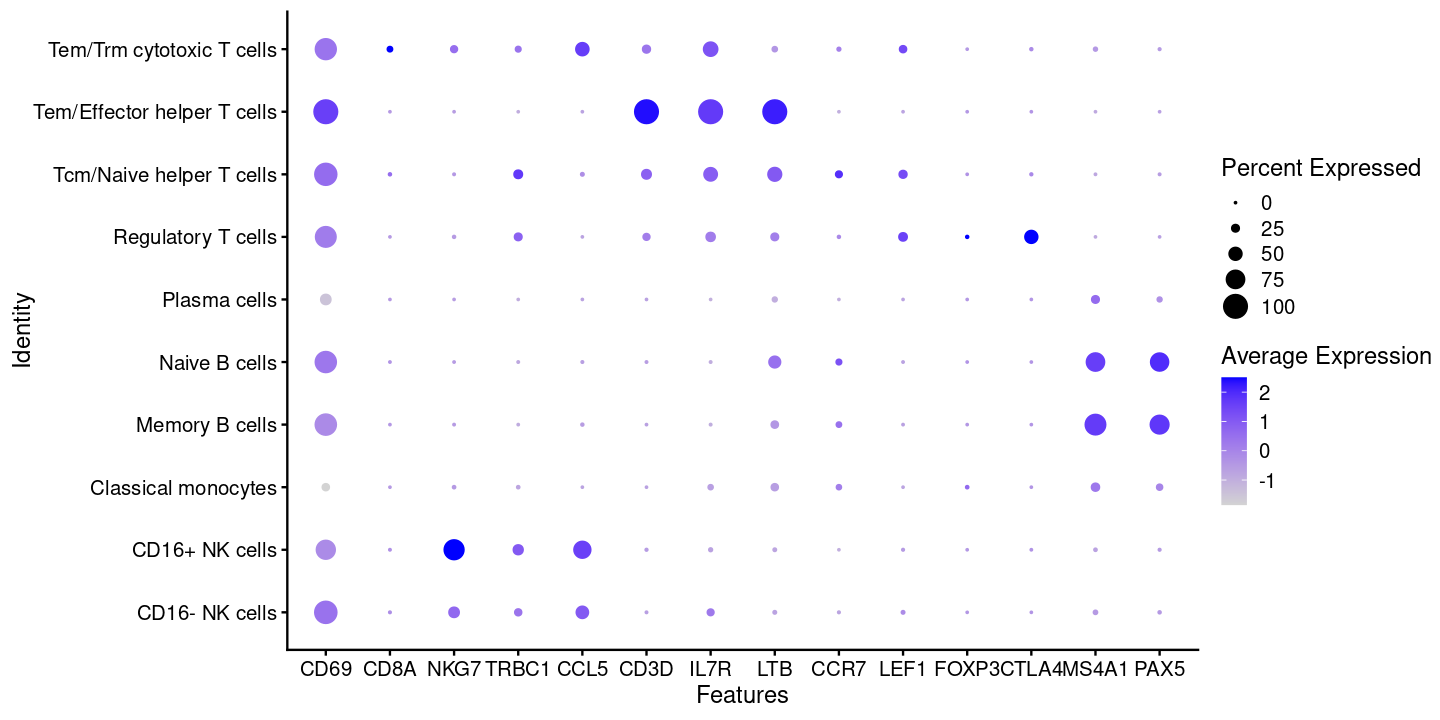

In [49]:
options(repr.plot.width=12, repr.plot.height=6)
marker.genes<-c("CD69", "CD8A", "NKG7", "TRBC1", "CCL5", 
                "IL7R", "LTB", 
               "CCR7","LEF1", "FOXP3", "CTLA4", "MS4A1", "PAX5")
DotPlot(subset(immune.combined, tissue.ident == "lungs"), features = marker.genes, group.by = "wsnn_MajorityVoting")
DotPlot(subset(immune.combined, tissue.ident == "spleens"), features = marker.genes, group.by = "wsnn_MajorityVoting")

In [19]:
pbmc.markers <- FindAllMarkers(immune.combined, group.by = "integrated_snn_res.0.5", only.pos = TRUE)
pbmc.markers %>%
    group_by(cluster) %>%
    dplyr::filter(avg_log2FC > 1) %>%
    dplyr::filter(!grepl("AC", gene)) %>%
    slice_head(n = 10) %>%
    ungroup() -> top
pdf("../output/Heatmap_integrated_marker_gene_expression.pdf", height = 12)
DoHeatmap(immune.combined, features = top$gene) + NoLegend()
dev.off()

Calculating cluster 0

Warning message:
"The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>."
Warning message:
"`PackageCheck()` was deprecated in SeuratObject 5.0.0.
ℹ Please use `rlang::check_installed()` instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>."
Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7

Calculating cluster 8

Calculating cluster 9

Calculating cluster 10

Calculating cluster 11

Calculating cluster 12

Calculating cluster 13

Calculating cluster 14

Calculating cluster 15

Warning message in DoHeatmap(immune.combined, features = top$gene):
"The following 

pdf 
  2

In [66]:
pbmc.markers %>%
    group_by(cluster) %>%
    dplyr::filter(avg_log2FC > 1 & p_val_adj < 0.05) %>%
    dplyr::filter(!grepl("AC", gene))

lapply(unique(pbmc.markers$cluster), function(i) {
    fname = gsub("/", "-", i)
    fname = gsub(" ", "_", fname)
    write.table(pbmc.markers[pbmc.markers$cluster == i, ], sprintf("../output/%s_DEG.csv", fname) , quote = F, row.names = F, sep = ",")
    })
    

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
0,1.664445,0.901,0.222,0,Naive B cells,BANK1
0,1.765600,0.870,0.232,0,Naive B cells,AFF3
0,2.859932,0.831,0.240,0,Naive B cells,HLA-DRA
0,2.271770,0.777,0.196,0,Naive B cells,MS4A1
0,1.845815,0.787,0.207,0,Naive B cells,ARHGAP24
0,1.724055,0.793,0.238,0,Naive B cells,RALGPS2
0,2.649329,0.741,0.186,0,Naive B cells,ADAM28
0,1.707519,0.739,0.199,0,Naive B cells,EBF1
0,2.336362,0.747,0.211,0,Naive B cells,HLA-DQA1


[[1]]
NULL

[[2]]
NULL

[[3]]
NULL

[[4]]
NULL

[[5]]
NULL

[[6]]
NULL

[[7]]
NULL

[[8]]
NULL

[[9]]
NULL

[[10]]
NULL

[[11]]
NULL

In [67]:
pdf("../output/Heatmap_WNN_marker_gene_expression.pdf")
pbmc.markers %>%
    group_by(cluster) %>%
    dplyr::filter(avg_log2FC > 1) %>%
    dplyr::filter(!grepl("AC", gene)) %>%
    slice_head(n = 5) %>%
    ungroup() -> top5
DoHeatmap(immune.combined, group.by = "wsnn_MajorityVoting", features = top5$gene) + NoLegend()
dev.off()

Warning message in DoHeatmap(immune.combined, group.by = "wsnn_MajorityVoting", :
"The following features were omitted as they were not found in the scale.data slot for the RNA assay: MCTP2, ZBTB16, STAM, DUSP16, BCL11B, KLRD1"


pdf 
  2

In [55]:
write.table(immune.combined@meta.data, "../output/lung_spleen_metadata.csv", row.names = T, quote = F, sep = ",")

## High read-depth datasets

We compared the number of RNA features in low vs. high read-depth datasets and found 95% of cells share similar distribution for number of genes detected. The number of cells are also comparable.

In [2]:
smo_rna <- readRDS("~/cluster/projects/u19_multiomics/scRNA-seq/SMO_preprocessed.RDS")

In [12]:
quantile(smo_rna@meta.data$nFeature_RNA, c(0, 0.5, 0.95))

0%  50%  95% 
   2 1157 2326

In [13]:
quantile(immune.combined@meta.data$nFeature_RNA, c(0, 0.5, 0.95))

0%  50%  95% 
 155 1123 2132

In [16]:
immune.combined

An object of class Seurat 
321136 features across 53647 samples within 4 assays 
Active assay: RNA (36601 features, 2000 variable features)
 3 layers present: counts, data, scale.data
 3 other assays present: ATAC, integrated, peaks
 6 dimensional reductions calculated: pca, umap, lsi, umap.atac, umap.rna, wnn.umap

In [17]:
smo_rna

An object of class Seurat 
171846 features across 61821 samples within 2 assays 
Active assay: RNA (36601 features, 0 variable features)
 1 layer present: counts
 1 other assay present: ATAC